# Assignment 3

- Fs = multiple filters (filter set)

In [1]:
# Import the necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import copy

In [2]:
# Prepare global variables
DATASET_DIR     = "../dataset/"     # Location of dataset
X_SHAPE         = (32, 32, 3)       # Shape of each image
NUM_FEATURES    = 32 * 32 * 3       # Number of features (pixels)
NUM_CLASSES     = 10                # Number of classes

## Data exploration

c:\Users\willi\Repositories\DD2424\.venv\Lib\site-packages\numpy\lib\_npyio_impl.py:494: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return pickle.load(fid, **pickle_kwargs)


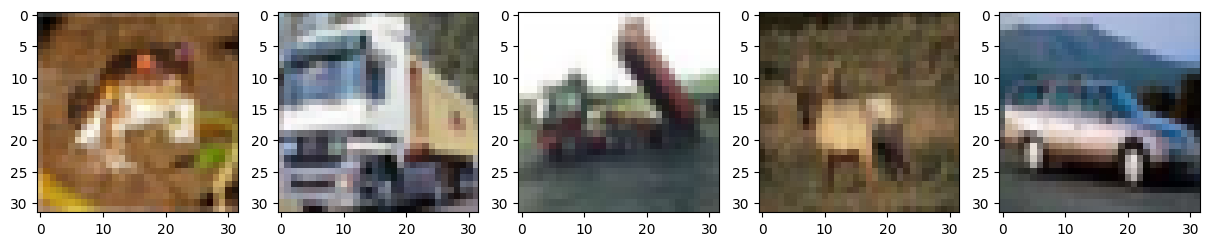

In [3]:
# Load data_batch_1
with open (DATASET_DIR + "data_batch_1", "rb") as f:
    data_batch_1 = np.load(f, allow_pickle=True, encoding="bytes")

# We extractthe image data and cast to float
X = data_batch_1[b"data"].astype(float)
# And transpose to get the images in the rows
X = X.T
# As the images are column vectors, we reshape
nn = X.shape[1]
X_img = X.reshape((32, 32,  3, nn), order="F")
X_img = np.transpose(X_img, (1, 0, 2, 3))

# Finally we print the first 5 images
fig, ax = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    ax[i].imshow(X_img[:, :, :, i].astype(int))
plt.show()

## Convolution

This test was done in order to make sure the comvolution was carried out correctly.

Note that the Convolution class holding the final methods are moved to the top of the document.

In [4]:
debug_file = 'debug_info.npz'
load_data = np.load(debug_file)
X = load_data['X']
Y = load_data['Y']
Fs = load_data['Fs']

print(f"X shape: {X.shape}")
print(f"Fs shape: (f f 3 nf) = {Fs.shape}")
print(f"f=4")
print(f"nf=2\n")

X_ims = np.transpose(X.reshape((32, 32, 3, 5), order='F'), (1, 0, 2, 3))

def conv(X, f, nf, n):
    res = np.zeros((32 // f, 32 // f, nf, n))
    for j in range(n):
        for x in range(0, 32, f):
            for y in range(0, 32, f):
                for i in range(nf):
                    res[x//f, y//f, i, j] = np.sum(X[x:x+f, y:y+f, :, j] * Fs[:, :, :, i])
    return res

# To test the convolution, we run the conv. function and compare
# the maximum absolute difference with the expected output (loaded
# from the provided file).
out = conv(X_ims, f=4, nf=2, n=5)
if np.max(np.abs(out - load_data['conv_outputs'])) == 0:
    print("Convolution test: passed")
else:
    print("Convolution test: failed")

class Convolution:

    def __init__(self):
        self.MX = None
        print(f"Initialized Convolution class")

    def compute_mx(self, X, n_p, f, n):
        MX = np.zeros((n_p, f**2 * 3, n))
        # For each image
        for i in range(n):
            # We iterate though each non-overlapping patch
            l = 0 #lth sub-region
            for x in range(0, 32, f):
                for y in range(0, 32, f):
                    # We extract the patch
                    X_patch = X[x:x+f, y:y+f, :, i]
                    # And store is using given instructions
                    MX[l, :, i] = X_patch.reshape((1, f*f*3), order='C')
                    l += 1
        self.MX = MX

    def conv(self, X, n_f, f, n):
        n_p = (32 // f) ** 2
        Convolution.compute_mx(self, X, n_p, f, n)
        Fs_flat = Fs.reshape((f*f*3, n_f), order='C')
        out = np.einsum('pkn,kf->pfn', self.MX, Fs_flat, optimize=True)
        return out.reshape((32//f, 32//f, n_f, n), order='C')
    
    def compute_grads(self, n, G, n_p, n_f):
        """
        Compute the gradients with respect to each filter.mro
        
        Args:
            n: Number of images
            MX: The matrix computed in the forward pass

        """
        MXt = np.transpose(self.MX, (1, 0, 2))
        GG = G.reshape((n_p, n_f, n), order='C')
        grad_Fs_flat = np.einsum('ijn, jln ->il', MXt, GG, optimize=True)
        return grad_Fs_flat

test_conv = Convolution()

# To test the convolution using matrix multiplication,
# we run the conv_matrix. function and compare
# the maximum absolute difference with the expected output (loaded
# from the provided file).
out_matrix = test_conv.conv(X_ims, n_f=2, f=4, n=5)
if np.max(np.abs(out_matrix - load_data['conv_outputs'])) < 1e-6:
    print("Convolution using matrix multiplication test: passed")
else:
    print("Convolution using matrix multiplication test: failed")

# Then we also test that the gradient calculation is correct by
# comparing it to load_data_['grad_Fs_flat'].
#G = Y - out_matrix
#n_p = (32 // 4) ** 2
#grad_Fs_flat = test_conv.compute_grads(n=5, G=G, n_p=n_p, n_f=2)
#if np.max(np.abs(grad_Fs_flat - load_data['grad_Fs_flat'])) < 1e-6:
#    print("Gradient calculation test: passed")
#else:
#    print("Gradient calculation test: failed")

X shape: (3072, 5)
Fs shape: (f f 3 nf) = (4, 4, 3, 2)
f=4
nf=2

Convolution test: passed
Initialized Convolution class
Convolution using matrix multiplication test: passed


In [5]:
for key in load_data.keys():
    print(key)

X
Y
y
Fs
fw
nf
Fs_flat
nh
W1
W2
b1
b2
MX
conv_outputs
conv_outputs_mat
conv_outputs_flattened
conv_flat
X1
P
grad_Fs_flat
grad_W1
grad_W2
grad_b1
grad_b2


## Data Handler Class

In [6]:
class DataHandler:
    """
    Class for data management, including loading, normalization and augmentation.

    Attributes:
        X_train: Array of shape (d, N_train) containing the training image data
        X_val: Array of shape (d, N_val) containing the validation image data
        X_test: Array of shape (d, N_test) containing the test image data

        Y_train: Array of shape (K, N_train) containing the one-hot-encoded training labels
        Y_val: Array of shape (K, N_val) containing the one-hot-encoded validation labels
        Y_test: Array of shape (K, N_test) containing the one-hot-encoded test labels

        y_train: Array of shape (N_train,) containing the integer training labels
        y_val: Array of shape (N_val,) containing the integer validation labels
        y_test: Array of shape (N_test,) containing the integer test labels

        d: Number of features (input dimension)
        K: Number of classes
        x_shape: Shape of images (e.g. (32, 32, 3) for CIFAR-10)
    """

    def __init__(self, train_files=None, val_files=None, test_files=None, normalize=True, d=None, k=None, x_shape=None):

        if train_files is None and val_files is None and test_files is None:
            raise ValueError("No files provided for Data initialization. Please provide at least one of train_files, val_files or test_files.")
        if d is None or k is None or x_shape is None:
            raise ValueError("Missing required parameters for Data initialization. Please provide arguments d, k and x_shape.")

        self.d = d
        self.K = k
        self.x_shape = x_shape

        if train_files is not None and len(train_files) > 0:
            self.X_train, self.Y_train, self.y_train = self.load_data_files(train_files)
        else:
            self.X_train, self.Y_train, self.y_train = [], [], []

        if val_files is not None and len(val_files) > 0:
            self.X_val, self.Y_val, self.y_val = self.load_data_files(val_files)
        else:
            self.X_val, self.Y_val, self.y_val = [], [], []

        if test_files is not None and len(test_files) > 0:
            self.X_test, self.Y_test, self.y_test = self.load_data_files(test_files)
        else:
            self.X_test, self.Y_test, self.y_test = [], [], []

        if normalize:
            self.normalize()

        self.n_p = (self.x_shape[0] // 4) ** 2
        self.n_f = 2

    def load_data_files(self, batch_file_list):
        """
        Loads single or multiple data files.

        Args:
            batch_file_list: A list of batch file names to load (e.g. ["data_batch_1", "data_batch_2"])

        Returns:
            X: Array of shape (d, N) containing the image data (N is total number of images)
            Y: Array of shape (K, N) containing the one-hot-encoded labels
            y: Array of shape (N,) containing the integer labels
        """
        X = []
        Y = []
        y = []
        for batch_file in batch_file_list:
            with open(DATASET_DIR + batch_file, "rb") as f:
                batch = np.load(f, allow_pickle=True, encoding="bytes")
            # Convert images to float
            X.append(batch[b"data"].astype(float).T)
            # Grab one-hot-encoded labels
            Y.append(np.zeros((self.K, X[-1].shape[1])))
            for i, label in enumerate(batch[b"labels"]):
                Y[-1][label, i] = 1
            # Grab labels
            y.append(np.array(batch[b"labels"], dtype=np.int64))
        # Flatten the lists into arrays
        X = np.concatenate(X, axis=1)
        Y = np.concatenate(Y, axis=1)
        y = np.concatenate(y, axis=0)
        print(f"Loaded total of {np.array(X).shape[1]} samples:")
        print(f"\tX shape: {np.array(X).shape}")
        print(f"\tY shape: {np.array(Y).shape}")
        print(f"\ty shape: {np.array(y).shape}\n")
        return X, Y, y
    
    def augment_image(self, X, prob):
        """
        Args:
            X: The input data, a 2D array of shape (d, N), where N is the number of images
            prob: The probability of performing each augmentation (horizontal flip and rotation)

        Returns:
            The augmented data same shape as the input
        """
        # We reshape the data into images (as done earlier)
        X = X.reshape(*self.x_shape, -1, order="F")
        X = np.transpose(X, (1, 0, 2, 3))
        # For each image, we perform data augmentation with a probability of prob
        for i in range(X.shape[3]):
            # We  add a chanse of horizontal flip
            if np.random.rand() < prob:
                X[:, :, :, i] = np.fliplr(X[:, :, :, i])
            # and check if we should rotate or not
            if np.random.rand() < prob:
                # We rotate the image by 90 degrees
                X[:, :, :, i] = np.rot90(X[:, :, :, i], k=1)
        # After augmentation we restore the original shape
        X = np.transpose(X, (1, 0, 2, 3))
        X = X.reshape(self.d, -1, order="F")

        return X
    
    @staticmethod
    def split_data(X, Y, y, train_size=0.8, val_size=0.1):
        """
        Splits data into training, validation and testing sets.

        Note that test_size is calculated as 1 - train_size - val_size.

        Args:
            X: Array of shape (:, N) containing the image data
            Y: Array of shape (:, N) containing the one-hot-encoded labels
            y: Array of shape (N,) containing the integer labels
            train_size: Proportion of training set
            val_size: Proportion of validation set

        Returns:
            X_train, Y_train, y_train: Training data and labels
            X_val, Y_val, y_val: Validation data and labels
            X_test, Y_test, y_test: Testing data and labels
        """
        n = X.shape[1]

        X_train = X[:, :int(train_size * n)]
        Y_train = Y[:, :int(train_size * n)]
        y_train = y[:int(train_size * n)]

        X_val = X[:, int(train_size * n):int((train_size + val_size) * n)]
        Y_val = Y[:, int(train_size * n):int((train_size + val_size) * n)]
        y_val = y[int(train_size * n):int((train_size + val_size) * n)]

        X_test = X[:, int((train_size + val_size) * n):]
        Y_test = Y[:, int((train_size + val_size) * n):]
        y_test = y[int((train_size + val_size) * n):]

        return X_train, Y_train, y_train, X_val, Y_val, y_val, X_test, Y_test, y_test
    
    def normalize(self):
        """
        Calculated mean standard deviation of training data and normalizes the data.
        This includes training, validation and test data.
        """
        mean = np.mean(self.X_train, axis=1).reshape(-1, 1)
        std = np.std(self.X_train, axis=1).reshape(-1, 1)
        self.X_train = (self.X_train - mean) / std
        self.X_val = (self.X_val - mean) / std
        self.X_test = (self.X_test - mean) / std

In [7]:
rng = np.random.default_rng()
# get the BitGenerator used by default_rng
BitGen = type(rng.bit_generator)
# use the state from a fresh bit generator
seed = 42
rng.bit_generator.state = BitGen(seed).state

## Neural Network Class

In [8]:
class Activation:
    @staticmethod
    def relu(X):
        """
        ReLu activation function.

        Args:
            X: Input array of shape (d, N)
        Returns:
            Output array of shape (d, N)
        """
        return np.maximum(0, X)
    @staticmethod
    def relu_derivative(G, X, Y):
        """
        ReLu derivative function.

        Args:
            G: Incoming gradient of shape (d, N)
            Y: Input array of shape (d, N) holding layer output
        Returns:
            Output array of shape (d, N)
        """
        return G * (Y > 0)

    @staticmethod
    def softmax(X):
        """
        Softmax activation function.

        Args:
            X: Input array of shape (K, N)
        Returns:
            Output array of shape (K, N)
        """
        exp_Z = np.exp(X - np.max(X, axis=0, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=0, keepdims=True)
    @staticmethod
    def softmax_derivative(G, X, Y):
        """
        Args:
            G: Incoming gradient (not used for cross-entropy + softmax case)
            X: Input array (pre-activation scores)
            Y: One-hot-encoded labels
        Returns:
            P - Y (the proper gradient for cross-entropy + softmax)
        """
        P = Activation.softmax(X)
        return P - Y  # Return P - Y_labels directly

In [9]:
class Layer:
    def update_params(self, eta):
        pass

In [10]:
class FullyConnectedLayer(Layer):
    def __init__(self, d, m, activation, lam = 0.):
        """
        Initializes the fully connected layer using He initilization
        for both weights and biases.

        Args:
            d: Input dim. (num. of features)
            m: Num. of neurons in the hidden layer
            activation: The activation function to use
            lam: Regularization strength
        """
        
        self.W = (1/np.sqrt(d))*rng.standard_normal(size = (m, d)) # He initialization
        self.b = np.zeros((m, 1))
        self.lam = lam

        if activation == "relu":
            self.activation_func = Activation.relu
            self.activation_func_derivative = Activation.relu_derivative
        elif activation == "softmax":
            self.activation_func = Activation.softmax
            self.activation_func_derivative = Activation.softmax_derivative
        else:
            print(f"Unsupported activation detected. Defaulting to ReLU.")
            self.activation_func = Activation.relu
            self.activation_func_derivative = Activation.relu_derivative


        self.Y = None
        self.N = None
        self.X = None

        self.grad_W = np.array([])
        self.grad_b = np.array([])

    def forward(self, X):
        """
        Forward pass.

        Args:
            X: Input data of shape (d, N)

        Returns:
            Output of shape (m, N)
        """
        self.Y = self.W @ X + self.b
        self.Z = self.activation_func(self.Y)
        self.N = X.shape[1]
        self.X = X
        return self.Z
    
    def backward(self, G, Y = None):
        """
        Backward pass.

        Args:
            G: Incoming gradient of shape (m, N)
            eta: Learning rate

        Returns:
            G_pass: Gradient to pass to the previous layer, of shape (d, N)
            W: Updated weights
            b: Updated biases
        """

        # Pass correct parameters to the activation function derivative
        if self.activation_func.__name__ == 'softmax' and Y is not None:
            G = self.activation_func_derivative(G, self.Y, Y)
        else:
            G = self.activation_func_derivative(G, self.Y, self.Z)

        G_pass = self.W.T @ G

        self.grad_W = (1 / self.N) * G @ self.X.T + 2 * self.lam * self.W
        self.grad_b = (1 / self.N) * np.sum(G, axis=1, keepdims=True)

        return G_pass, self.W, self.b
    
    def update_params(self, eta):
        """
        Updates the weights and biases using the computed gradients.

        Args:
            eta: Learning rate
        """
        self.W -= eta * self.grad_W
        self.b -= eta * self.grad_b

In [11]:
class ConvolutionalLayer(Layer):
    def __init__(self, f, n_f, activation, lam = 0.):
        """
        Initializes the convolutional layer.

        Args:
            f: Filter size (4 for 4x4 filters)
            n_f: Num. of filters
            activation: The activation function to use
            lam: Regularization strength
        """
        self.f = f
        self.n_f = n_f
        self.lam = lam
        self.n = None
        self.n_p = (32 // f) ** 2 # Num. of patches per image

        self.b = np.zeros((n_f, 1))
        self.b_grads = np.zeros_like(self.b)

        if activation == "relu":
            self.activation_func = Activation.relu
            self.activation_func_derivative = Activation.relu_derivative
        elif activation == "softmax":
            self.activation_func = Activation.softmax
            self.activation_func_derivative = Activation.softmax_derivative
        else:
            print(f"Unsupported activation detected. Defaulting to ReLU.")
            self.activation_func = Activation.relu
            self.activation_func_derivative = Activation.relu_derivative

        self.Fs = (1/np.sqrt(f*f*3))*rng.standard_normal(size=(f, f, 3, n_f)) # He initialization
        self.Fs_grads = np.zeros_like(self.Fs)

    def compute_mx(self, X, f, n):
        """
        Computes the MX matrix for convolution using matrix multiplication.
        This function was created earlier during testing phase.

        Args:
            X: Input data of shape (32, 32, 3, n)
            f: Filter size
            n: Number of images

        Returns:
            MX: Matrix of shape (n_p, f**2 * 3, n)
        """
        MX = np.zeros((self.n_p, f**2 * 3, n))
        # For each image
        for i in range(n):
            # We iterate though each non-overlapping patch
            l = 0 #lth sub-region
            for x in range(0, 32, f):
                for y in range(0, 32, f):
                    # We extract the patch
                    X_patch = X[x:x+f, y:y+f, :, i]
                    # And store is using given instructions
                    MX[l, :, i] = X_patch.reshape((1, f*f*3), order='C')
                    l += 1
        self.MX = MX

    def forward(self, X):
        """
        Forward pass.

        Args:
            X: Input data of shape (d, N)
        """
        self.n = X.shape[1]
        x_img = X.reshape((32, 32, 3, self.n), order='F')
        self.compute_mx(x_img, self.f, self.n)
        Fs_flat = self.Fs.reshape((self.f*self.f*3, self.n_f), order='C')
        out = np.einsum('pkn,kf->pfn', self.MX, Fs_flat, optimize=True)
        self.Y = out.reshape((32//self.f, 32//self.f, self.n_f, self.n), order='C')
        self.Y += self.b  # Add bias
        self.Z = self.activation_func(self.Y)
        return self.Z
    
    def backward(self, G):
        """
        Compute the gradients with respect to each filter.mro
        
        Args:
            n: Number of images
            MX: The matrix computed in the forward pass

        """

        # First apply derivative of activation function
        G = self.activation_func_derivative(G, self.Y, self.Z)

        # Then we compute the filter gradients
        GG = G.reshape((self.n_p, self.n_f, self.n), order='C')

        MXt = np.transpose(self.MX, (1, 0, 2)) # (provided)
        grad_Fs_flat = np.einsum('ijn, jln ->il', MXt, GG, optimize=True) # (provided)
        
        self.Fs_grads = (1 / self.n) * grad_Fs_flat.reshape(self.Fs.shape, order='C')
        self.b_grads = (1 / self.n) * np.sum(GG, axis=(0, 2), keepdims=True).reshape(self.b.shape) + 2 * self.lam * self.b

        #print(f"Fs_grads.shape: {self.Fs_grads.shape}")

        # Finally we compuate and return input gradient
        Fs_flat = self.Fs.reshape((self.f*self.f*3, self.n_f), order='C')
        G_X_flat = np.einsum('kf, pfn ->pkn', Fs_flat, GG, optimize=True)
        G_X = G_X_flat.reshape((-1, self.n), order='C')
        return G_X
    
    def update_params(self, eta):
        self.Fs -= eta * self.Fs_grads
        self.b -= eta * self.b_grads

In [12]:
class FlattenLayer(Layer):
    def __init__(self):
        self.input_shape = None

    def forward(self, X):
        """
        Flatten in foward pass.

        Args:
            X: Input data
        """
        self.input_shape = X.shape
        #print(f"student: shape before flatten: {X.shape}")
        X = np.transpose(X, (2, 0, 1, 3))
        X = X.reshape(-1, X.shape[-1], order='C')
        #print(f"student: shape after flatten: {X.shape}")
        return X
    def backward(self, G):
        """
        Unflatten in backward pass.

        Args:
            G: Incoming gradient of shape (d, N)
        """        
        # Reshape back to (C, H, W, N)
        G = G.reshape((self.input_shape[2], self.input_shape[0], self.input_shape[1], self.input_shape[3]), order='C')
        # Transpose back to (H, W, C, N)
        return np.transpose(G, (1, 2, 0, 3))

In [13]:
class NeuralNetwork:
    """
    Neural Network class. Collect all relevant methods here for simplicity and modularity.

    Attributes:
        d: Number of features (input dimension)
        m: Number of hidden units
        net: Dictionary containing the weights and biases of the network
        lam: Regularization strength
    """

    def __init__(self):
        """
        Initialize network with weights and biases.

        Args:
            d: Number of features (input dimension)
            m: Number of hidden units
            lam: Regularization strength
        """

        #self.d = d
        #self.m = m
        #self.lam = lam
        self.layers = []
        self.output_layer = None

        self.training_loss_history = None
        self.validation_loss_history = None
        self.training_cost_history = None
        self.validation_cost_history = None
        self.training_acc_history = None
        self.validation_acc_history = None

    def print_structure(self):
        """
        Print layer structure of the network.
        """
        for i in range(len(self.layers)):
            layer = self.layers[i]
            print(f"Layer #{i+1}: {layer.W[0].shape[0]} neurons, activation: {layer.activation_func.__name__}")

    def get_grads(self):
        """
        Get gradients for weights and biases for each layer.
        This function is used for compatability with provided
        teached code and testing.
        """
        grads = dict(W=[], b=[], Fs=[], Fs_b=[])
        for layer in self.layers:
            if layer.__class__.__name__ == "ConvolutionalLayer":
                grads['Fs'].append(layer.Fs_grads)
                grads['Fs_b'].append(layer.b_grads)
            elif layer.__class__.__name__ == "FullyConnectedLayer":
                grads['W'].append(layer.grad_W)
                grads['b'].append(layer.grad_b)
        return grads
    
    def get_weights_and_biases(self):
        """
        Get weights and biases for each layer.
        This function is used for compatability with
        the teachers provided testing code.
        """
        net = dict(W=[], b=[], Fs=[], Fs_b=[])
        for layer in self.layers:
            if layer.__class__.__name__ == "FullyConnectedLayer":
                net['W'].append(layer.W)
                net['b'].append(layer.b)
            elif layer.__class__.__name__ == "ConvolutionalLayer":
                net['Fs'].append(layer.Fs)
                net['Fs_b'].append(layer.b)
        return net

    def add_layer(self, layers):
        """
        Add a layer to the network.

        Args:
            layer: An instance of a layer class
        """
        for l in layers:
            self.layers.append(l)
            self.output_layer = l
        
    def apply_network(self, X):
        """
        Apply network forward pass. Stores and returns the output of each layer (after activation).

        Args:
            X: Array of shape (d, N) containing the input data

        Returns:
             layer_output: List of arrays holding the output of each layer (after activation)
        """
        for layer in self.layers:
            X = layer.forward(X)
        return X
    
    def compute_loss(self, P, y):
        """
        Compute loss using cross-entropy and L2 regularization.

        Args:
            P: Array of shape (K, N) containing the predicted probabilities for each class and sample
            y: Array of shape (N,) containing the integer labels for each sample

        Returns:
            loss: The computed loss value
        """
        loss = (1 / P.shape[1]) * -np.sum(np.log(P[y, np.arange(P.shape[1])]))
        return loss
    
    def compute_cost(self, P, y):
        """
        Compute cost using cross-entropy and L2 regularization.

        Note that this only supports weights from fully connected (dense)
        layers and not for convolutional layers.

        Args:
            P: Array of shape (K, N) containing the predicted probabilities for each class and sample
            y: Array of shape (N,) containing the integer labels for each sample

        Returns:
            cost: The computed cost value
        """
        weight_sum = 0
        for layer in self.layers:
            if layer.__class__.__name__ == "FullyConnectedLayer":
                weight_sum += np.sum(layer.W ** 2)
            elif layer.__class__.__name__ == "ConvolutionalLayer":
                weight_sum += np.sum(layer.Fs ** 2)
        regularization = self.output_layer.lam * weight_sum
        return self.compute_loss(P, y) + regularization
    
    def compute_acc(self, P, y):
        """
        Compute accuracy of predictions.

        Args:
            P: Array of shape (K, N) containing the predicted probabilities for each class and sample
            y: Array of shape (N,) containing the integer labels for each sample
    
        Returns:
            acc: The computed accuracy value
        """
        predicted_labels = np.argmax(P, axis=0)
        acc = np.mean(predicted_labels == y)
        return acc
        
    def backward_pass(self, X, Y):
        """
        Backward pass to compute gradients of weights and biases.

        Args:
            X: Array of shape (d, N) containing the input data
            Y: Array of shape (K, N) containing the one-hot-encoded labels
            layer_output: List of arrays holding the output of each layer (after activation)

        Returns:
            gradients: Dictionary containing the gradients of weights and biases for each layer
        """
        G = None
        for i, l in enumerate(reversed(self.layers)):
            # We only pass Y if we're at the output layer
            Y_pass = Y if i == 0 else None
            if l.__class__.__name__ == "ConvolutionalLayer":
                G = l.backward(G)
            elif l.__class__.__name__ == "FullyConnectedLayer":
                G, W, b = l.backward(G, Y=Y_pass)
            elif l.__class__.__name__ == "FlattenLayer":
                G = l.backward(G)

    def mini_batch_gd(
            self,
            rng,
            loss_func,
            cost_func,
            data_handler,
            GDparams,
            cyclical_lr=None, 
            verbose=2,
            record_every=1
        ):
        """
        Mini-batch gradient descent.

        Args:
            rng: Random number generator (passed for reproducibility)
            loss_func: Function to compute the loss (cross-entropy)
            cost_func: Function to compute the cost (loss + regularization)
            data_handler: DataHandler object containing the training and validation data
            GDparams: Dictionary holding the parameters for gradient descent (n_batch, eta, n_epochs)
            cyclical_lr: Dictionary holding parameters for cyclical learning rate (n_s, eta_min, eta_max) or None for no cyclical learning rate
            verbose: Level of verbosity for printing progress and plotting results (0 = no output, 1 = print progress, 2 = print progress and plot results)
            record_every: Number of epochs between recording loss and cost history for plotting
        """
        # And extract parameters
        n_batch = GDparams['n_batch']
        eta = GDparams['eta']
        n_epochs = GDparams['n_epochs']
        n_train = data_handler.X_train.shape[1]
        # And prepare a loss and cost history lists
        training_loss_history = []
        validation_loss_history = []
        training_cost_history = []
        validation_cost_history = []
        training_acc_history = []
        validation_acc_history = []
        # For each epoch
        t = 0
        for _epoch in range(n_epochs):
            # We first shuffle the data
            perm = rng.permutation(n_train)
            X_train_shuffled = data_handler.X_train[:, perm]
            Y_train_shuffled = data_handler.Y_train[:, perm]
            y_train_shuffled = data_handler.y_train[perm]
            # Data augmentation
            #X_train_shuffled = augment_image(X_train_shuffled, prob=0.5)

            # Then we perform per mini-batch updates
            for j in range(n_train//n_batch): # Changed from / to // for integer division
                j_start = j*n_batch
                j_end = (j+1)*n_batch
                X_batch = X_train_shuffled[:, j_start:j_end]
                Y_batch = Y_train_shuffled[:, j_start:j_end]
                #y_batch = y_train_shuffled[j_start:j_end]

                # Cyclical learning rate
                if not cyclical_lr is None:
                    n_s = cyclical_lr['n_s']
                    eta_min = cyclical_lr['eta_min']
                    eta_max = cyclical_lr['eta_max']

                    l = t % (2 * n_s)

                    if cyclical_lr['increasing_step_sizes']:
                        if t > 0 and t % (2 * n_s) == 0:
                            cyclical_lr['n_s'] = n_s * 2
                            n_s = cyclical_lr['n_s']

                    if l < n_s:
                        eta = eta_min + l / n_s * (eta_max - eta_min)
                    else:
                        eta = eta_max - (l - n_s) / n_s * (eta_max - eta_min)
                    t += 1

                # We apply the network and compute the gradients
                self.apply_network(X_batch)
                self.backward_pass(X_batch, Y_batch)
                # Finally we update the weights and biases
                for layer in self.layers:
                    layer.update_params(eta)

            # At the end of the epoch, we compute the training loss
            # and validation loss and store them in the history lists
            # for later comparison
            P_train = self.apply_network(data_handler.X_train)
            train_loss = loss_func(P_train, data_handler.y_train)
            training_loss_history.append(train_loss)
            train_cost = cost_func(P_train, data_handler.y_train)
            training_cost_history.append(train_cost)

            P_val = self.apply_network(data_handler.X_val)
            val_loss = loss_func(P_val, data_handler.y_val)
            validation_loss_history.append(val_loss)
            val_cost = cost_func(P_val, data_handler.y_val)
            validation_cost_history.append(val_cost)

            train_acc = self.compute_acc(P_train, data_handler.y_train)
            training_acc_history.append(train_acc)
            val_acc = self.compute_acc(P_val, data_handler.y_val)
            validation_acc_history.append(val_acc)

            # We print the training and validation loss at the end of each epoch
            # to monitor the process
            if verbose >= 1:
                print(f"Epoch {_epoch+1}/{n_epochs}, Train. Loss: {training_loss_history[-1]:.4f}, Val. Loss: {validation_loss_history[-1]:.4f}, Train. Acc: {training_acc_history[-1]:.4f}, Val. Acc: {validation_acc_history[-1]:.4f}")

        # Before returning, we plot the training and
        # validation loss & cost history using matplotlib

        if verbose >= 2:
            fig, ax = plt.subplots(1, 3, figsize=(15, 5))

            n_batches_per_epoch = data_handler.X_train.shape[1] // GDparams['n_batch']
            updates_recorded = np.arange(len(training_cost_history)) * record_every * n_batches_per_epoch

            ax[1].plot(updates_recorded, training_cost_history, label='Training', color='green')
            ax[1].plot(updates_recorded, validation_cost_history, label='Validation', color='red')
            ax[1].set_xlabel('Update Step')
            ax[1].set_ylabel('Cost')
            ax[1].legend()
            
            ax[0].plot(updates_recorded, training_loss_history, label='Training', color='green')
            ax[0].plot(updates_recorded, validation_loss_history, label='Validation', color='red')
            ax[0].set_xlabel('Update Step')
            ax[0].set_ylabel('Loss')
            ax[0].legend()

            ax[2].plot(updates_recorded, training_acc_history, label='Training', color='green')
            ax[2].plot(updates_recorded, validation_acc_history, label='Validation', color='red')
            ax[2].set_xlabel('Update Step')
            ax[2].set_ylabel('Accuracy')
            ax[2].legend()

            plt.tight_layout()
            plt.show()

        # Store all history lists in the class attributes for later use
        self.training_loss_history = training_loss_history
        self.validation_loss_history = validation_loss_history
        self.training_cost_history = training_cost_history
        self.validation_cost_history = validation_cost_history
        self.training_acc_history = training_acc_history
        self.validation_acc_history = validation_acc_history

    def cyclic_mini_batch_gd(
            self,
            rng,
            loss_func,
            cost_func,
            data_handler,
            GDparams,
            cyclical_lr, 
            verbose=2,
            record_every=1,
            label_smoothing = None
        ):
        """
        Cyclic mini-batch gradient descent.

        Args:
            rng: Random number generator (passed for reproducibility)
            loss_func: Function to compute the loss (cross-entropy)
            cost_func: Function to compute the cost (loss + regularization)
            data_handler: DataHandler object containing the training and validation data
            GDparams: Dictionary holding the parameters for gradient descent (n_batch)
            cyclical_lr: Dictionary holding parameters for cyclical learning rate (n_s, eta_min, eta_max) or None for no cyclical learning rate
            verbose: Level of verbosity for printing progress and plotting results (0 = no output, 1 = print progress, 2 = print progress and plot results)
        """
        # And extract parameters
        n_batch = GDparams['n_batch']
        cycles = cyclical_lr['cycles']
        n_train = data_handler.X_train.shape[1]
        # And prepare a loss and cost history lists
        training_loss_history = []
        validation_loss_history = []
        training_cost_history = []
        validation_cost_history = []
        training_acc_history = []
        validation_acc_history = []
        # 
        t = 0
        t_in_cycle = 0
        cycle = 0
        n_s = cyclical_lr['n_s']
        eta_min = cyclical_lr['eta_min']
        eta_max = cyclical_lr['eta_max']
        increasing_step_sizes = cyclical_lr.get('increasing_step_sizes', False)
        # Label smoothing
        Y_smooth = None
        Y = data_handler.Y_train
        if not label_smoothing is None:
            Y_smooth = np.copy(data_handler.Y_train.T)
            for Y in Y_smooth:
                Y[Y == 1] = 1 - label_smoothing
                Y[Y == 0] = label_smoothing / (Y.shape[0] - 1)
            Y_smooth = Y_smooth.T
            Y = Y_smooth
        
        # For each cycle
        while cycle < cycles:
            # We first shuffle the data
            perm = rng.permutation(n_train)
            X_train_shuffled = data_handler.X_train[:, perm]
            Y_train_shuffled = Y[:, perm]
            #y_train_shuffled = data_handler.y_train[perm]
            # Data augmentation
            #X_train_shuffled = augment_image(X_train_shuffled, prob=0.5)

            # Then we perform per mini-batch updates
            for j in range(n_train//n_batch): # Changed from / to // for integer division
                j_start = j*n_batch
                j_end = (j+1)*n_batch
                X_batch = X_train_shuffled[:, j_start:j_end]
                Y_batch = Y_train_shuffled[:, j_start:j_end]
                #y_batch = y_train_shuffled[j_start:j_end]

                l = t_in_cycle % (2 * n_s)

                eta = None

                if t_in_cycle < n_s:
                    eta = eta_min + l / n_s * (eta_max - eta_min)
                else:
                    eta = eta_max - (l - n_s) / n_s * (eta_max - eta_min)

                t += 1
                t_in_cycle += 1

                if t_in_cycle == 2 * n_s:
                    cycle += 1
                    if cycle >= cycles:
                        break
                    if increasing_step_sizes:
                        n_s *= 2
                    t_in_cycle = 0

                # We apply the network and compute the gradients
                self.apply_network(X_batch)
                self.backward_pass(X_batch, Y_batch)
                # Finally we update the weights and biases
                for layer in self.layers:
                    layer.update_params(eta)

            if cycle >= cycles:
                break

            # At the end of the cycle, we compute the training loss
            # and validation loss and store them in the history lists
            # for later comparison
            P_train = self.apply_network(data_handler.X_train)
            train_loss = loss_func(P_train, data_handler.y_train)
            training_loss_history.append(train_loss)
            train_cost = cost_func(P_train, data_handler.y_train)
            training_cost_history.append(train_cost)

            P_val = self.apply_network(data_handler.X_val)
            val_loss = loss_func(P_val, data_handler.y_val)
            validation_loss_history.append(val_loss)
            val_cost = cost_func(P_val, data_handler.y_val)
            validation_cost_history.append(val_cost)

            train_acc = self.compute_acc(P_train, data_handler.y_train)
            training_acc_history.append(train_acc)
            val_acc = self.compute_acc(P_val, data_handler.y_val)
            validation_acc_history.append(val_acc)

            # We print the training and validation loss at the end of each update
            # to monitor the process
            if verbose >= 1:
                print(f"Cycle {cycle+1}/{cycles}, Train. Loss: {training_loss_history[-1]:.4f}, Val. Loss: {validation_loss_history[-1]:.4f}, Train. Acc: {training_acc_history[-1]:.4f}, Val. Acc: {validation_acc_history[-1]:.4f}")

        # Before returning, we plot the training and
        # validation loss & cost history using matplotlib

        if verbose >= 2:
            fig, ax = plt.subplots(1, 3, figsize=(15, 5))

            n_batches_per_ = data_handler.X_train.shape[1] // GDparams['n_batch']
            updates_recorded = np.arange(len(training_cost_history)) * record_every * n_batches_per_

            ax[1].plot(updates_recorded, training_cost_history, label='Training', color='green')
            ax[1].plot(updates_recorded, validation_cost_history, label='Validation', color='red')
            ax[1].set_xlabel('Update Step')
            ax[1].set_ylabel('Cost')
            ax[1].legend()
            
            ax[0].plot(updates_recorded, training_loss_history, label='Training', color='green')
            ax[0].plot(updates_recorded, validation_loss_history, label='Validation', color='red')
            ax[0].set_xlabel('Update Step')
            ax[0].set_ylabel('Loss')
            ax[0].legend()

            ax[2].plot(updates_recorded, training_acc_history, label='Training', color='green')
            ax[2].plot(updates_recorded, validation_acc_history, label='Validation', color='red')
            ax[2].set_xlabel('Update Step')
            ax[2].set_ylabel('Accuracy')
            ax[2].legend()

            plt.tight_layout()
            plt.show()

        # Store all history lists in the class attributes for later use
        self.training_loss_history = training_loss_history
        self.validation_loss_history = validation_loss_history
        self.training_cost_history = training_cost_history
        self.validation_cost_history = validation_cost_history
        self.training_acc_history = training_acc_history
        self.validation_acc_history = validation_acc_history

### Test that the forward pass works

In [14]:
test_net = NeuralNetwork()
test_net.add_layer([
    FullyConnectedLayer(d=NUM_FEATURES, m=50, activation="relu", lam=0),
    FullyConnectedLayer(d=50, m=NUM_CLASSES, activation="relu", lam=0)
])

# We run a small test on a subset
try:
    res = test_net.apply_network(X[:, :100])
    print("apply_network test passed")
except Exception as e:
    print("apply_network test failed")
    print(e)

apply_network test passed


### Prepare a small dataset and compare gradients

In [15]:
data_small = DataHandler(
    train_files=["data_batch_1"],
    val_files=["data_batch_2"],
    test_files=["test_batch"],
    normalize=True,
    d=NUM_FEATURES,
    k=NUM_CLASSES,
    x_shape=X_SHAPE,
)

Loaded total of 10000 samples:
	X shape: (3072, 10000)
	Y shape: (10, 10000)
	y shape: (10000,)

Loaded total of 10000 samples:
	X shape: (3072, 10000)
	Y shape: (10, 10000)
	y shape: (10000,)

Loaded total of 10000 samples:
	X shape: (3072, 10000)
	Y shape: (10, 10000)
	y shape: (10000,)



In [16]:
from torch_gradient_computations import ComputeGradsWithTorch

d_small = 5
n_small = 3
m = 6
lam = 0
small_net = NeuralNetwork()
small_net.add_layer([
    FullyConnectedLayer(d=d_small, m=m, activation="relu", lam=0),
    FullyConnectedLayer(d=m, m=10, activation="softmax", lam=0),
])

X_train_small = data_small.X_train[0:d_small, 0:n_small]
Y_train_small = data_small.Y_train[:, 0:n_small]
y_train_small = data_small.y_train[0:n_small]

small_net.apply_network(X_train_small)

small_net.backward_pass(X_train_small, Y_train_small)
my_grads = small_net.get_grads()
weight_and_biases = small_net.get_weights_and_biases()
torch_grads = ComputeGradsWithTorch(X_train_small, y_train_small, weight_and_biases)

In [17]:
# We compare my grads with the ground truth from Torch
# First we check absolute difference (if < 1e-6, then it's ok)
abs_diff_W_0 = np.abs(my_grads['W'][0] - torch_grads['W'][0])
abs_diff_b_0 = np.abs(my_grads['b'][0] - torch_grads['b'][0])
assert np.all(abs_diff_W_0 < 1e-6), "backward_pass gradients W[0] do not match Torch gradients"
assert np.all(abs_diff_b_0 < 1e-6), "backward_pass gradients b[0] do not match Torch gradients"
abs_diff_W_1 = np.abs(my_grads['W'][1] - torch_grads['W'][1])
abs_diff_b_1 = np.abs(my_grads['b'][1] - torch_grads['b'][1])
assert np.all(abs_diff_W_1 < 1e-6), "backward_pass gradients W[1] do not match Torch gradients"
assert np.all(abs_diff_b_1 < 1e-6), "backward_pass gradients b[1] do not match Torch gradients"
# As this approachmay fail with small numbers, we also check
# for relative error using the formula:
# abs(my_grad - torch_grad) / (abs(my_grad) + abs(torch_grad)) < 1e-6
relative_error_w_0 = np.abs(my_grads['W'][0] - torch_grads['W'][0]) / (np.abs(my_grads['W'][0]) + np.abs(torch_grads['W'][0]) + 1e-12)
relative_error_b_0 = np.abs(my_grads['b'][0] - torch_grads['b'][0]) / (np.abs(my_grads['b'][0]) + np.abs(torch_grads['b'][0]) + 1e-12)
assert np.all(relative_error_w_0 < 1e-6), "backward_pass gradients W[0] do not match Torch gradients (relative error)"
assert np.all(relative_error_b_0 < 1e-6), "backward_pass gradients b[0] do not match Torch gradients (relative error)"
relative_error_w_1 = np.abs(my_grads['W'][1] - torch_grads['W'][1]) / (np.abs(my_grads['W'][1]) + np.abs(torch_grads['W'][1]) + 1e-12)
relative_error_b_1 = np.abs(my_grads['b'][1] - torch_grads['b'][1]) / (np.abs(my_grads['b'][1]) + np.abs(torch_grads['b'][1]) + 1e-12)
assert np.all(relative_error_w_1 < 1e-6), "backward_pass gradients W[1] do not match Torch gradients (relative error)"
assert np.all(relative_error_b_1 < 1e-6), "backward_pass gradients b[1] do not match Torch gradients (relative error)"


Gradient calculations are OK!

In [45]:
"""
data_small = DataHandler(
    train_files=["data_batch_1"],
    val_files=["data_batch_2"],
    test_files=["test_batch"],
    normalize=True,
    d=NUM_FEATURES,
    k=NUM_CLASSES,
    x_shape=X_SHAPE,
)

data_small.X_train = data_small.X_train[:, :100]
data_small.y_train = data_small.y_train[:100]
data_small.X_val = data_small.X_val[:, :100]
data_small.y_val = data_small.y_val[:100]
data_small.X_test = data_small.X_test[:, :100]
data_small.y_test = data_small.y_test[:100]

data_small.normalize()

GDparams = {
    'n_batch': 1,
    'eta': 0.001,
    'n_epochs': 200
}

lam = 0
rng = np.random.default_rng(42)

net = NeuralNetwork()
net.add_layer([
    FullyConnectedLayer(d=NUM_FEATURES, m=50, activation="relu", lam=lam),
    FullyConnectedLayer(d=50, m=NUM_CLASSES, activation="softmax", lam=lam),
])

net.mini_batch_gd(rng, net.compute_loss, net.compute_cost, data_small, GDparams, cyclical_lr=None, verbose=2)

acc = net.compute_acc(net.apply_network(data_small.X_test), data_small.y_test)
print(f"Test accuracy: {acc:.4f}")
"""

'\ndata_small = DataHandler(\n    train_files=["data_batch_1"],\n    val_files=["data_batch_2"],\n    test_files=["test_batch"],\n    normalize=True,\n    d=NUM_FEATURES,\n    k=NUM_CLASSES,\n    x_shape=X_SHAPE,\n)\n\ndata_small.X_train = data_small.X_train[:, :100]\ndata_small.y_train = data_small.y_train[:100]\ndata_small.X_val = data_small.X_val[:, :100]\ndata_small.y_val = data_small.y_val[:100]\ndata_small.X_test = data_small.X_test[:, :100]\ndata_small.y_test = data_small.y_test[:100]\n\ndata_small.normalize()\n\nGDparams = {\n    \'n_batch\': 1,\n    \'eta\': 0.001,\n    \'n_epochs\': 200\n}\n\nlam = 0\nrng = np.random.default_rng(42)\n\nnet = NeuralNetwork()\nnet.add_layer([\n    FullyConnectedLayer(d=NUM_FEATURES, m=50, activation="relu", lam=lam),\n    FullyConnectedLayer(d=50, m=NUM_CLASSES, activation="softmax", lam=lam),\n])\n\nnet.mini_batch_gd(rng, net.compute_loss, net.compute_cost, data_small, GDparams, cyclical_lr=None, verbose=2)\n\nacc = net.compute_acc(net.apply_n

In [46]:
"""
data_small = DataHandler(
    train_files=["data_batch_1", "data_batch_2", "data_batch_3", "data_batch_4"],
    val_files=["data_batch_5"],
    test_files=["test_batch"],
    normalize=True,
    d=NUM_FEATURES,
    k=NUM_CLASSES,
    x_shape=X_SHAPE,
)

GDparams = {
    'n_batch': 100,
    'eta': 0.01,
    'n_epochs': 10,
}

cyclical_lr = {
    'eta_min': 1e-5,
    'eta_max': 1e-1,
    'n_s': 500 # step size for cyclical learning rate
}
lam = .01

lam = 0
rng = np.random.default_rng(42)

net = NeuralNetwork()
net.add_layer([
    FullyConnectedLayer(d=NUM_FEATURES, m=50, activation="relu", lam=lam),
    FullyConnectedLayer(d=50, m=NUM_CLASSES, activation="softmax", lam=lam),
])

net.mini_batch_gd(rng, net.compute_loss, net.compute_cost, data_small, GDparams, cyclical_lr, verbose=2)

acc = net.compute_acc(net.apply_network(data_small.X_test), data_small.y_test)
print(f"Test accuracy: {acc:.4f}")
"""

'\ndata_small = DataHandler(\n    train_files=["data_batch_1", "data_batch_2", "data_batch_3", "data_batch_4"],\n    val_files=["data_batch_5"],\n    test_files=["test_batch"],\n    normalize=True,\n    d=NUM_FEATURES,\n    k=NUM_CLASSES,\n    x_shape=X_SHAPE,\n)\n\nGDparams = {\n    \'n_batch\': 100,\n    \'eta\': 0.01,\n    \'n_epochs\': 10,\n}\n\ncyclical_lr = {\n    \'eta_min\': 1e-5,\n    \'eta_max\': 1e-1,\n    \'n_s\': 500 # step size for cyclical learning rate\n}\nlam = .01\n\nlam = 0\nrng = np.random.default_rng(42)\n\nnet = NeuralNetwork()\nnet.add_layer([\n    FullyConnectedLayer(d=NUM_FEATURES, m=50, activation="relu", lam=lam),\n    FullyConnectedLayer(d=50, m=NUM_CLASSES, activation="softmax", lam=lam),\n])\n\nnet.mini_batch_gd(rng, net.compute_loss, net.compute_cost, data_small, GDparams, cyclical_lr, verbose=2)\n\nacc = net.compute_acc(net.apply_network(data_small.X_test), data_small.y_test)\nprint(f"Test accuracy: {acc:.4f}")\n'

In [47]:
"""
data_small = DataHandler(
    train_files=["data_batch_1", "data_batch_2", "data_batch_3", "data_batch_4"],
    val_files=["data_batch_5"],
    test_files=["test_batch"],
    normalize=True,
    d=NUM_FEATURES,
    k=NUM_CLASSES,
    x_shape=X_SHAPE,
)

GDparams = {
    'n_batch': 100,
    'eta': 0.01,
    'n_epochs': 10,
}

cyclical_lr = {
    'eta_min': 1e-5,
    'eta_max': 1e-1,
    'n_s': 500 # step size for cyclical learning rate
}
lam = .01

lam = 0
rng = np.random.default_rng(42)

net = NeuralNetwork()
net.add_layer([
    ConvolutionalLayer(f=4, n_f=10, activation="relu", lam=lam),
    FlattenLayer(),
    FullyConnectedLayer(d=640, m=50, activation="relu", lam=lam),
    FullyConnectedLayer(d=50, m=NUM_CLASSES, activation="softmax", lam=lam),
])

net.mini_batch_gd(rng, net.compute_loss, net.compute_cost, data_small, GDparams, cyclical_lr, verbose=2)

acc = net.compute_acc(net.apply_network(data_small.X_test), data_small.y_test)
print(f"Test accuracy: {acc:.4f}")
"""

'\ndata_small = DataHandler(\n    train_files=["data_batch_1", "data_batch_2", "data_batch_3", "data_batch_4"],\n    val_files=["data_batch_5"],\n    test_files=["test_batch"],\n    normalize=True,\n    d=NUM_FEATURES,\n    k=NUM_CLASSES,\n    x_shape=X_SHAPE,\n)\n\nGDparams = {\n    \'n_batch\': 100,\n    \'eta\': 0.01,\n    \'n_epochs\': 10,\n}\n\ncyclical_lr = {\n    \'eta_min\': 1e-5,\n    \'eta_max\': 1e-1,\n    \'n_s\': 500 # step size for cyclical learning rate\n}\nlam = .01\n\nlam = 0\nrng = np.random.default_rng(42)\n\nnet = NeuralNetwork()\nnet.add_layer([\n    ConvolutionalLayer(f=4, n_f=10, activation="relu", lam=lam),\n    FlattenLayer(),\n    FullyConnectedLayer(d=640, m=50, activation="relu", lam=lam),\n    FullyConnectedLayer(d=50, m=NUM_CLASSES, activation="softmax", lam=lam),\n])\n\nnet.mini_batch_gd(rng, net.compute_loss, net.compute_cost, data_small, GDparams, cyclical_lr, verbose=2)\n\nacc = net.compute_acc(net.apply_network(data_small.X_test), data_small.y_test)\n

In [48]:
data_small = DataHandler(
    train_files=["data_batch_1"],
    val_files=["data_batch_2"],
    test_files=["test_batch"],
    normalize=True,
    d=NUM_FEATURES,
    k=NUM_CLASSES,
    x_shape=X_SHAPE,
)

data_small.X_train = data_small.X_train[:, :10]
data_small.Y_train = data_small.Y_train[:, :10]
data_small.y_train = data_small.y_train[:10]

data_small.X_val = data_small.X_val[:, :10]
data_small.Y_val = data_small.Y_val[:, :10]
data_small.y_val = data_small.y_val[:10]

data_small.X_test = data_small.X_test[:, :10]
data_small.Y_test = data_small.Y_test[:, :10]
data_small.y_test = data_small.y_test[:10]

data_small.normalize()

GDparams = {
    'n_batch': 1,
    'eta': 0.001,
    'n_epochs': 200
}

lam = 0
rng = np.random.default_rng(42)

net = NeuralNetwork()
net.add_layer([
    ConvolutionalLayer(f=4, n_f=10, activation="relu", lam=lam),
    FlattenLayer(),
    FullyConnectedLayer(d=640, m=50, activation="relu", lam=lam),
    FullyConnectedLayer(d=50, m=NUM_CLASSES, activation="softmax", lam=lam),
])

net.apply_network(data_small.X_train)
net.backward_pass(data_small.X_train, data_small.Y_train)

torch_grads = ComputeGradsWithTorch(
    data_small.X_train.reshape((32, 32, 3, -1), order='F').transpose((3, 2, 0, 1)),
    data_small.y_train,
    net.get_weights_and_biases()
)

my_grads = net.get_grads()

for f_i in range(len(my_grads['Fs'])):
    abs_diff_Fs = np.abs(my_grads['Fs'][f_i] - torch_grads['Fs'][f_i])
    assert np.all(abs_diff_Fs < 1e-6), f"backward_pass gradients Fs[{f_i}] do not match Torch gradients"
    relative_error_Fs = np.abs(my_grads['Fs'][f_i] - torch_grads['Fs'][f_i]) / (np.abs(my_grads['Fs'][f_i]) + np.abs(torch_grads['Fs'][f_i]) + 1e-12)
    assert np.all(relative_error_Fs < 1e-6), f"backward_pass gradients Fs[{f_i}] do not match Torch gradients (relative error)"

for b_i in range(len(my_grads['Fs_b'])):
    abs_diff_b = np.abs(my_grads['Fs_b'][b_i] - torch_grads['Fs_b'][b_i])
    assert np.all(abs_diff_b < 1e-6), f"backward_pass gradients Fs_b[{b_i}] do not match Torch gradients"
    relative_error_b = np.abs(my_grads['Fs_b'][b_i] - torch_grads['Fs_b'][b_i]) / (np.abs(my_grads['Fs_b'][b_i]) + np.abs(torch_grads['Fs_b'][b_i]) + 1e-12)
    assert np.all(relative_error_b < 1e-6), f"backward_pass gradients Fs_b[{b_i}] do not match Torch gradients (relative error)"

for b_i in range(len(my_grads['b'])):
    abs_diff_b = np.abs(my_grads['b'][b_i] - torch_grads['b'][b_i])
    assert np.all(abs_diff_b < 1e-6), f"backward_pass gradients b[{b_i}] do not match Torch gradients"

for w_i in range(len(my_grads['W'])):
    abs_diff_W = np.abs(my_grads['W'][w_i] - torch_grads['W'][w_i])
    assert np.all(abs_diff_W < 1e-6), f"backward_pass gradients W[{w_i}] do not match Torch gradients"
    relative_error_w = np.abs(my_grads['W'][w_i] - torch_grads['W'][w_i]) / (np.abs(my_grads['W'][w_i]) + np.abs(torch_grads['W'][w_i]) + 1e-12)
    assert np.all(relative_error_w < 1e-6), f"backward_pass gradients W[{w_i}] do not match Torch gradients (relative error)"

Loaded total of 10000 samples:
	X shape: (3072, 10000)
	Y shape: (10, 10000)
	y shape: (10000,)

Loaded total of 10000 samples:
	X shape: (3072, 10000)
	Y shape: (10, 10000)
	y shape: (10000,)

Loaded total of 10000 samples:
	X shape: (3072, 10000)
	Y shape: (10, 10000)
	y shape: (10000,)



c:\Users\willi\Repositories\DD2424\.venv\Lib\site-packages\numpy\lib\_npyio_impl.py:494: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return pickle.load(fid, **pickle_kwargs)


Loaded total of 50000 samples:
	X shape: (3072, 50000)
	Y shape: (10, 50000)
	y shape: (50000,)

Loaded total of 10000 samples:
	X shape: (3072, 10000)
	Y shape: (10, 10000)
	y shape: (10000,)

Cycle 1/3, Train. Loss: 1.6589, Val. Loss: 1.6984, Train. Acc: 0.4124, Val. Acc: 0.4050
Cycle 1/3, Train. Loss: 1.4300, Val. Loss: 1.4725, Train. Acc: 0.4932, Val. Acc: 0.4700
Cycle 1/3, Train. Loss: 1.2797, Val. Loss: 1.3455, Train. Acc: 0.5493, Val. Acc: 0.5170
Cycle 2/3, Train. Loss: 1.2900, Val. Loss: 1.3664, Train. Acc: 0.5454, Val. Acc: 0.5080
Cycle 2/3, Train. Loss: 1.3306, Val. Loss: 1.4054, Train. Acc: 0.5329, Val. Acc: 0.4970
Cycle 2/3, Train. Loss: 1.1848, Val. Loss: 1.2893, Train. Acc: 0.5862, Val. Acc: 0.5490
Cycle 3/3, Train. Loss: 1.1566, Val. Loss: 1.2643, Train. Acc: 0.5947, Val. Acc: 0.5520
Cycle 3/3, Train. Loss: 1.2127, Val. Loss: 1.3191, Train. Acc: 0.5778, Val. Acc: 0.5300
Cycle 3/3, Train. Loss: 1.1477, Val. Loss: 1.2594, Train. Acc: 0.6024, Val. Acc: 0.5610


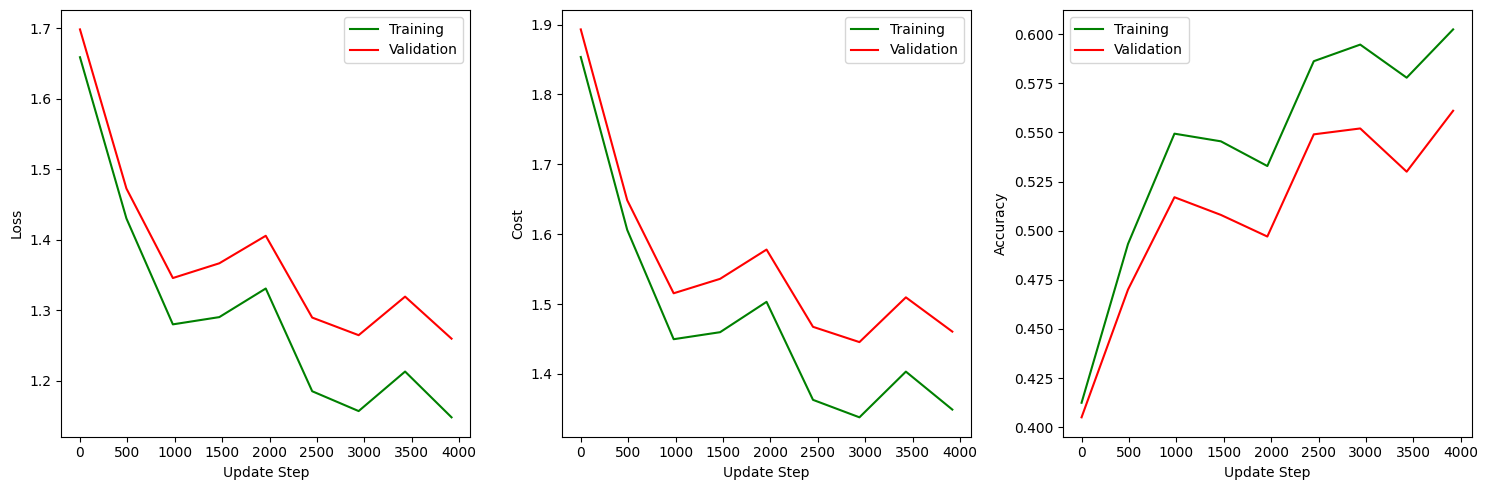

Test accuracy: 0.5692


In [18]:
data = DataHandler(
    train_files=["data_batch_1", "data_batch_2", "data_batch_3", "data_batch_4", "data_batch_5"],
    val_files=[],
    test_files=["test_batch"],
    normalize=True,
    d=NUM_FEATURES,
    k=NUM_CLASSES,
    x_shape=X_SHAPE,
)
data.X_val = data.X_train[:, 49000:]
data.Y_val = data.Y_train[:, 49000:]
data.y_val = data.y_train[49000:]

data.X_train = data.X_train[:, :49000]
data.Y_train = data.Y_train[:, :49000]
data.y_train = data.y_train[:49000]

data.normalize()

GDparams = {
    'n_batch': 100,
}


cyclical_lr = {
    'eta_min': 1e-5,
    'eta_max': 1e-1,
    'n_s': 800, # step size for cyclical learning rate
    'increasing_step_sizes': False,
    'cycles': 3
}
lam = .003

rng = np.random.default_rng(42)

net = NeuralNetwork()
net.add_layer([
    ConvolutionalLayer(f=4, n_f=10, activation="relu", lam=lam),
    FlattenLayer(),
    FullyConnectedLayer(d=640, m=50, activation="relu", lam=lam),
    FullyConnectedLayer(d=50, m=NUM_CLASSES, activation="softmax", lam=lam),
])

net.cyclic_mini_batch_gd(rng, net.compute_loss, net.compute_cost, data, GDparams, cyclical_lr, verbose=2)

acc = net.compute_acc(net.apply_network(data.X_test), data.y_test)
print(f"Test accuracy: {acc:.4f}")

About 57.17% in 120s. Though object based implementation.

In [50]:
import time

explore_params = [
    {'f': 2, 'n_f': 3},
    {'f': 4, 'n_f': 10},
    {'f': 8, 'n_f': 40},
    {'f': 16, 'n_f': 160},
]
performance_results = []
training_times = []
for params in explore_params:
    f = params['f']
    n_f = params['n_f']

    print(f"Training using filter size {f} and {n_f} filters...")

    rng = np.random.default_rng(42)

    net = NeuralNetwork()
    net.add_layer([
        ConvolutionalLayer(f=f, n_f=n_f, activation="relu", lam=lam),
        FlattenLayer(),
        FullyConnectedLayer(d=(32//f)*(32//f)*n_f, m=50, activation="relu", lam=lam),
        FullyConnectedLayer(d=50, m=NUM_CLASSES, activation="softmax", lam=lam),
    ])

    start_time = time.time()
    net.cyclic_mini_batch_gd(rng, net.compute_loss, net.compute_cost, data, GDparams, cyclical_lr, verbose=0)
    end_time = time.time()

    acc = net.compute_acc(net.apply_network(data.X_test), data.y_test)

    performance_results.append(acc)
    training_times.append(end_time - start_time)

    print(f"Filter size: {f}, Num. filters: {n_f}, Test acc: {acc:.4f}, Training time: {end_time - start_time:.2f} (s)")

Training using filter size 2 and 3 filters...
Filter size: 2, Num. filters: 3, Test acc: 0.5018, Training time: 314.15 (s)
Training using filter size 4 and 10 filters...
Filter size: 4, Num. filters: 10, Test acc: 0.5692, Training time: 99.99 (s)
Training using filter size 8 and 40 filters...
Filter size: 8, Num. filters: 40, Test acc: 0.5808, Training time: 61.14 (s)
Training using filter size 16 and 160 filters...
Filter size: 16, Num. filters: 160, Test acc: 0.5731, Training time: 51.03 (s)


C:\Users\willi\AppData\Local\Temp\ipykernel_22864\1856722235.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


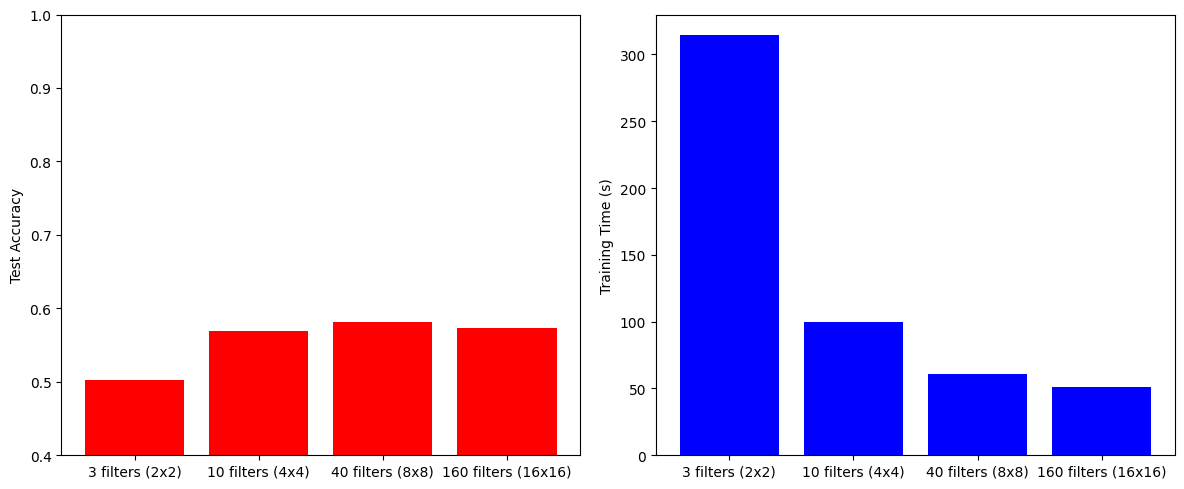

In [51]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

performance_results = np.array(performance_results)
training_times = np.array(training_times)
filters_sizes = [params['f'] for params in explore_params]
num_of_filters = [params['n_f'] for params in explore_params]

combinations = [f"{n_f} filters ({f}x{f})" for f, n_f in zip(filters_sizes, num_of_filters)]

ax[0].bar(range(len(filters_sizes)), performance_results, color='red')
ax[0].set_ylabel('Test Accuracy')
ax[0].set_xticks(range(len(filters_sizes)))
ax[0].set_xticklabels(combinations)
ax[0].set_ylim(0.4, 1)

ax[1].bar(range(len(num_of_filters)), training_times, color='blue')
ax[1].set_ylabel('Training Time (s)')
ax[1].set_xticks(range(len(num_of_filters)))
ax[1].set_xticklabels(combinations)

fig.tight_layout()
fig.show()

In [52]:
data = DataHandler(
    train_files=["data_batch_1", "data_batch_2", "data_batch_3", "data_batch_4", "data_batch_5"],
    val_files=[],
    test_files=["test_batch"],
    normalize=True,
    d=NUM_FEATURES,
    k=NUM_CLASSES,
    x_shape=X_SHAPE,
)
data.X_val = data.X_train[:, 49000:]
data.Y_val = data.Y_train[:, 49000:]
data.y_val = data.y_train[49000:]

data.X_train = data.X_train[:, :49000]
data.Y_train = data.Y_train[:, :49000]
data.y_train = data.y_train[:49000]

data.normalize()

c:\Users\willi\Repositories\DD2424\.venv\Lib\site-packages\numpy\lib\_npyio_impl.py:494: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return pickle.load(fid, **pickle_kwargs)


Loaded total of 50000 samples:
	X shape: (3072, 50000)
	Y shape: (10, 50000)
	y shape: (50000,)

Loaded total of 10000 samples:
	X shape: (3072, 10000)
	Y shape: (10, 10000)
	y shape: (10000,)



Training using filter size 4 and 10 filters...
Cycle 1/3, Train. Loss: 1.6589, Val. Loss: 1.6984, Train. Acc: 0.4124, Val. Acc: 0.4050
Cycle 1/3, Train. Loss: 1.4300, Val. Loss: 1.4725, Train. Acc: 0.4932, Val. Acc: 0.4700
Cycle 1/3, Train. Loss: 1.2797, Val. Loss: 1.3455, Train. Acc: 0.5493, Val. Acc: 0.5170
Cycle 2/3, Train. Loss: 1.2734, Val. Loss: 1.3548, Train. Acc: 0.5536, Val. Acc: 0.5200
Cycle 2/3, Train. Loss: 1.3030, Val. Loss: 1.3894, Train. Acc: 0.5389, Val. Acc: 0.5080
Cycle 2/3, Train. Loss: 1.2632, Val. Loss: 1.3601, Train. Acc: 0.5570, Val. Acc: 0.5290
Cycle 2/3, Train. Loss: 1.2109, Val. Loss: 1.2944, Train. Acc: 0.5766, Val. Acc: 0.5460
Cycle 2/3, Train. Loss: 1.1545, Val. Loss: 1.2635, Train. Acc: 0.5984, Val. Acc: 0.5490
Cycle 2/3, Train. Loss: 1.1044, Val. Loss: 1.2240, Train. Acc: 0.6154, Val. Acc: 0.5700
Cycle 3/3, Train. Loss: 1.0734, Val. Loss: 1.2029, Train. Acc: 0.6274, Val. Acc: 0.5740
Cycle 3/3, Train. Loss: 1.0857, Val. Loss: 1.2207, Train. Acc: 0.6218, Va

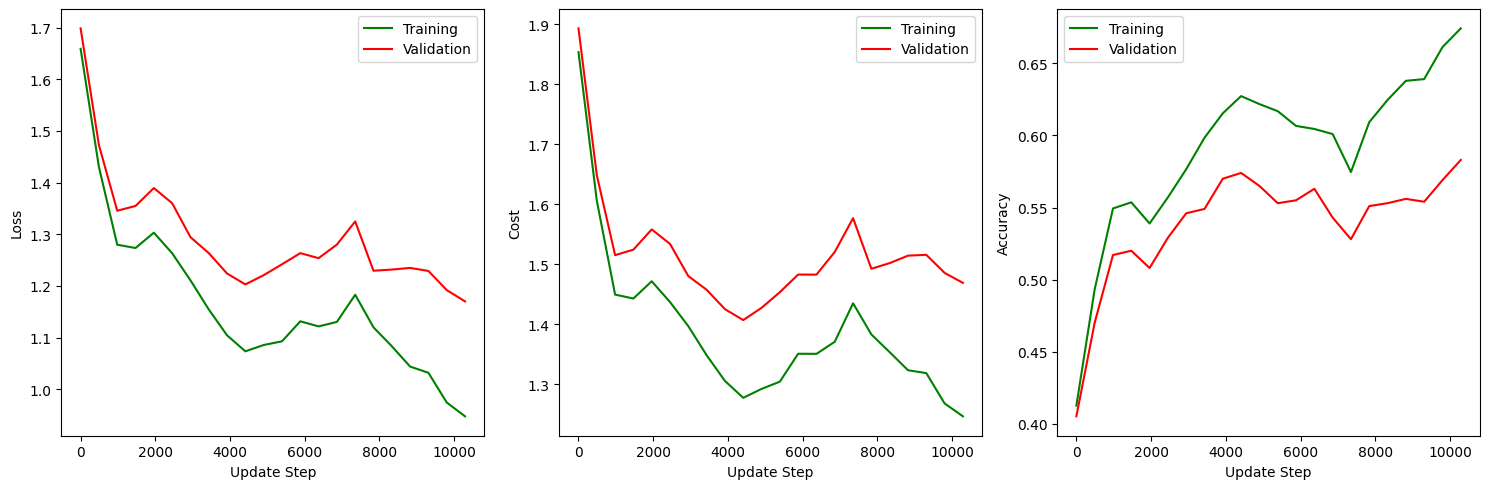

Filter size: 4, Num. filters: 10, Test acc: 0.5847, Training time: 239.86 (s)
Training using filter size 8 and 40 filters...
Cycle 1/3, Train. Loss: 1.6196, Val. Loss: 1.6349, Train. Acc: 0.4206, Val. Acc: 0.4210
Cycle 1/3, Train. Loss: 1.3966, Val. Loss: 1.4341, Train. Acc: 0.5032, Val. Acc: 0.5090
Cycle 1/3, Train. Loss: 1.2661, Val. Loss: 1.3385, Train. Acc: 0.5568, Val. Acc: 0.5420
Cycle 2/3, Train. Loss: 1.2559, Val. Loss: 1.3236, Train. Acc: 0.5596, Val. Acc: 0.5420
Cycle 2/3, Train. Loss: 1.2349, Val. Loss: 1.3188, Train. Acc: 0.5703, Val. Acc: 0.5490
Cycle 2/3, Train. Loss: 1.2044, Val. Loss: 1.2750, Train. Acc: 0.5817, Val. Acc: 0.5540
Cycle 2/3, Train. Loss: 1.1711, Val. Loss: 1.2603, Train. Acc: 0.5914, Val. Acc: 0.5490
Cycle 2/3, Train. Loss: 1.1118, Val. Loss: 1.2392, Train. Acc: 0.6146, Val. Acc: 0.5820
Cycle 2/3, Train. Loss: 1.0445, Val. Loss: 1.1772, Train. Acc: 0.6372, Val. Acc: 0.6090
Cycle 3/3, Train. Loss: 1.0145, Val. Loss: 1.1675, Train. Acc: 0.6524, Val. Acc: 0.

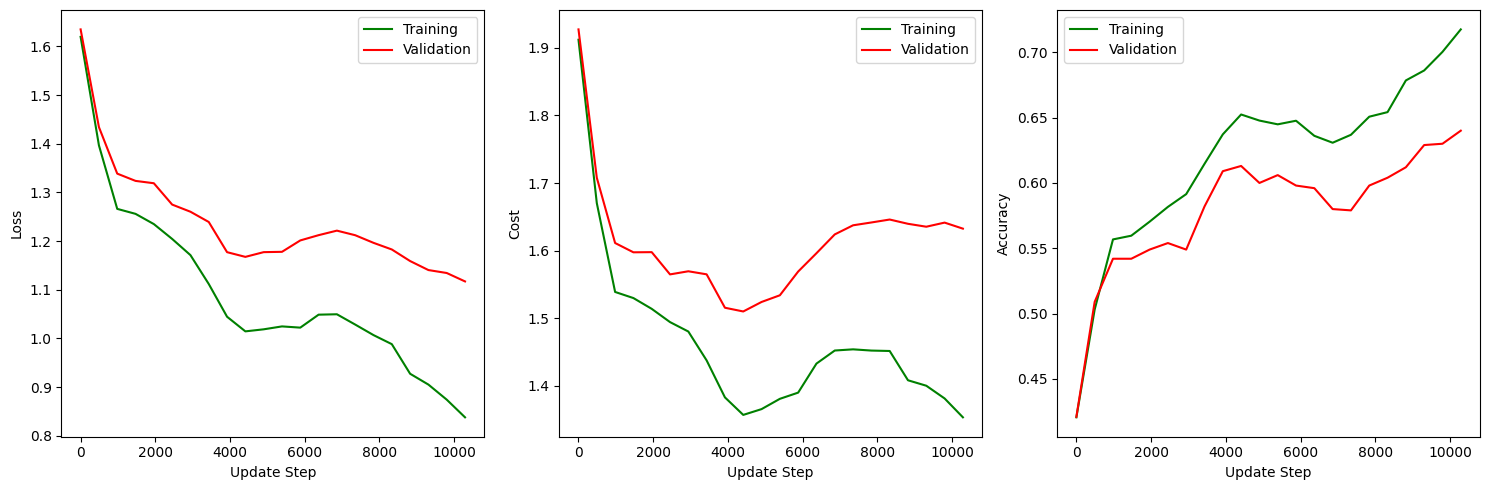

Filter size: 8, Num. filters: 40, Test acc: 0.6110, Training time: 124.20 (s)


In [53]:
import time

explore_params = [
    {'f': 4, 'n_f': 10},
    {'f': 8, 'n_f': 40},
]
performance_results = []
training_times = []

for params in explore_params:
    f = params['f']
    n_f = params['n_f']

    # Note that we must keep this in the loop as mini_batch_gd
    # will be updating the step sizes and we want to have the same
    # starting point for each combination of parameters.
    cyclical_lr = {
        'eta_min': 1e-5,
        'eta_max': 1e-1,
        'n_s': 800, # step size for cyclical learning rate
        'increasing_step_sizes': True,
        'cycles': 3
    }

    print(f"Training using filter size {f} and {n_f} filters...")

    rng = np.random.default_rng(42)

    net = NeuralNetwork()
    net.add_layer([
        ConvolutionalLayer(f=f, n_f=n_f, activation="relu", lam=lam),
        FlattenLayer(),
        FullyConnectedLayer(d=(32//f)*(32//f)*n_f, m=50, activation="relu", lam=lam),
        FullyConnectedLayer(d=50, m=NUM_CLASSES, activation="softmax", lam=lam),
    ])

    start_time = time.time()
    net.cyclic_mini_batch_gd(rng, net.compute_loss, net.compute_cost, data, GDparams, cyclical_lr, verbose=2)
    end_time = time.time()

    acc = net.compute_acc(net.apply_network(data.X_test), data.y_test)

    performance_results.append(acc)
    training_times.append(end_time - start_time)

    print(f"Filter size: {f}, Num. filters: {n_f}, Test acc: {acc:.4f}, Training time: {end_time - start_time:.2f} (s)")

Filter size: 8, Num. filters: 40, Test acc: 0.6110, Training time: 281.02 (s)


Training using filter size 4 and 40 filters...
Cycle 1/3, Train. Loss: 1.5123, Val. Loss: 1.5414, Train. Acc: 0.4634, Val. Acc: 0.4450
Cycle 1/3, Train. Loss: 1.2653, Val. Loss: 1.3225, Train. Acc: 0.5531, Val. Acc: 0.5310
Cycle 1/3, Train. Loss: 1.1155, Val. Loss: 1.2182, Train. Acc: 0.6143, Val. Acc: 0.5690
Cycle 2/3, Train. Loss: 1.0968, Val. Loss: 1.1943, Train. Acc: 0.6204, Val. Acc: 0.5780
Cycle 2/3, Train. Loss: 1.0596, Val. Loss: 1.1806, Train. Acc: 0.6358, Val. Acc: 0.5680
Cycle 2/3, Train. Loss: 1.1088, Val. Loss: 1.2266, Train. Acc: 0.6044, Val. Acc: 0.5710
Cycle 2/3, Train. Loss: 0.9887, Val. Loss: 1.1557, Train. Acc: 0.6554, Val. Acc: 0.5980
Cycle 2/3, Train. Loss: 0.8898, Val. Loss: 1.0768, Train. Acc: 0.6993, Val. Acc: 0.6150
Cycle 2/3, Train. Loss: 0.8312, Val. Loss: 1.0707, Train. Acc: 0.7179, Val. Acc: 0.6270
Cycle 3/3, Train. Loss: 0.7892, Val. Loss: 1.0450, Train. Acc: 0.7361, Val. Acc: 0.6320
Cycle 3/3, Train. Loss: 0.7868, Val. Loss: 1.0549, Train. Acc: 0.7341, Va

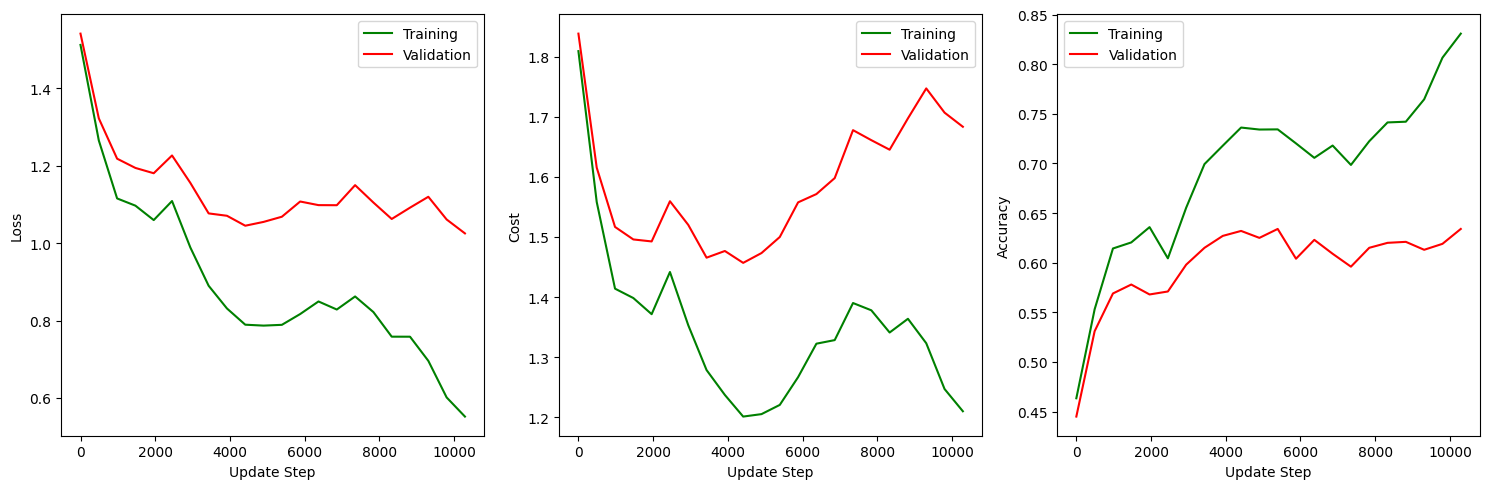

Filter size: 4, Num. filters: 40, Test acc: 0.6431, Training time: 267.16 (s)


In [54]:
import time

explore_params = [
    {'f': 4, 'n_f': 40},
]
performance_results = []
training_times = []

for params in explore_params:
    f = params['f']
    n_f = params['n_f']

    # Note that we must keep this in the loop as mini_batch_gd
    # will be updating the step sizes and we want to have the same
    # starting point for each combination of parameters.
    cyclical_lr = {
        'eta_min': 1e-5,
        'eta_max': 1e-1,
        'n_s': 800, # step size for cyclical learning rate
        'increasing_step_sizes': True,
        'cycles': 3
    }

    print(f"Training using filter size {f} and {n_f} filters...")

    rng = np.random.default_rng(42)

    net = NeuralNetwork()
    net.add_layer([
        ConvolutionalLayer(f=f, n_f=n_f, activation="relu", lam=lam),
        FlattenLayer(),
        FullyConnectedLayer(d=(32//f)*(32//f)*n_f, m=50, activation="relu", lam=lam),
        FullyConnectedLayer(d=50, m=NUM_CLASSES, activation="softmax", lam=lam),
    ])

    start_time = time.time()
    net.cyclic_mini_batch_gd(rng, net.compute_loss, net.compute_cost, data, GDparams, cyclical_lr, verbose=2)
    end_time = time.time()

    acc = net.compute_acc(net.apply_network(data.X_test), data.y_test)

    performance_results.append(acc)
    training_times.append(end_time - start_time)

    print(f"Filter size: {f}, Num. filters: {n_f}, Test acc: {acc:.4f}, Training time: {end_time - start_time:.2f} (s)")

Training using filter size 4 and 40 filters...
Cycle 1/3, Train. Loss: 1.4997, Val. Loss: 1.5136, Train. Acc: 0.4783, Val. Acc: 0.4700
Cycle 1/3, Train. Loss: 1.2301, Val. Loss: 1.3073, Train. Acc: 0.5726, Val. Acc: 0.5340
Cycle 1/3, Train. Loss: 1.0630, Val. Loss: 1.1753, Train. Acc: 0.6344, Val. Acc: 0.5870
Cycle 2/3, Train. Loss: 1.0450, Val. Loss: 1.1704, Train. Acc: 0.6400, Val. Acc: 0.5850
Cycle 2/3, Train. Loss: 1.0238, Val. Loss: 1.1630, Train. Acc: 0.6479, Val. Acc: 0.5910
Cycle 2/3, Train. Loss: 0.9897, Val. Loss: 1.1834, Train. Acc: 0.6552, Val. Acc: 0.5740
Cycle 2/3, Train. Loss: 0.9117, Val. Loss: 1.1807, Train. Acc: 0.6836, Val. Acc: 0.5700
Cycle 2/3, Train. Loss: 0.7365, Val. Loss: 1.0598, Train. Acc: 0.7547, Val. Acc: 0.6210
Cycle 2/3, Train. Loss: 0.6237, Val. Loss: 1.0037, Train. Acc: 0.8022, Val. Acc: 0.6570
Cycle 3/3, Train. Loss: 0.5708, Val. Loss: 0.9993, Train. Acc: 0.8276, Val. Acc: 0.6550
Cycle 3/3, Train. Loss: 0.5650, Val. Loss: 1.0244, Train. Acc: 0.8275, Va

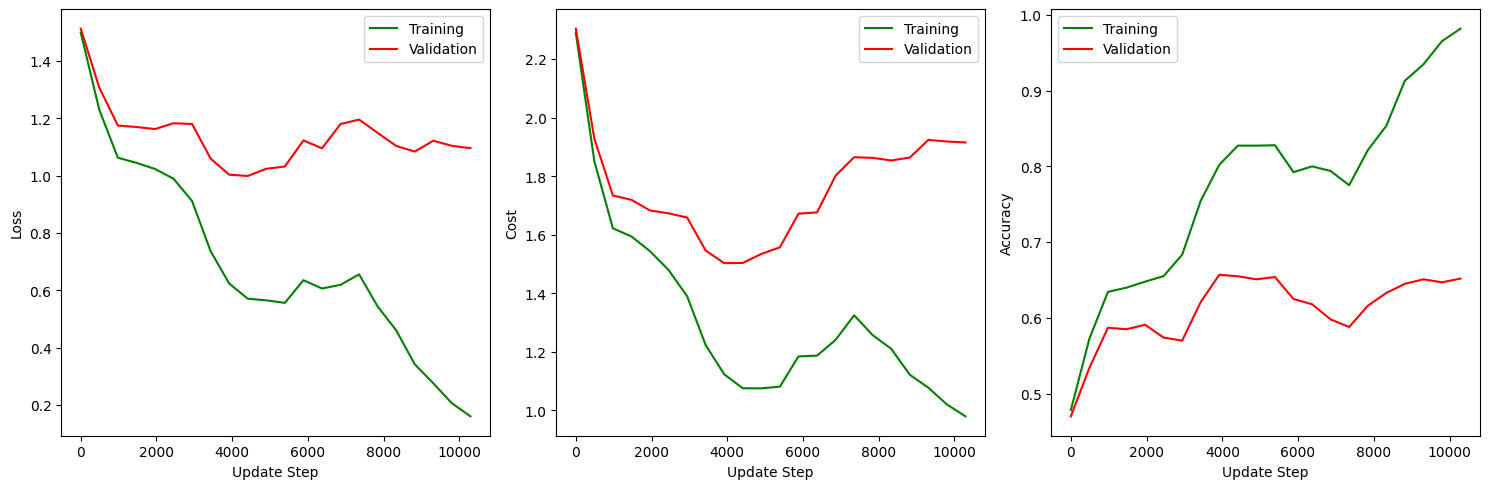

Filter size: 4, Num. filters: 40, Test acc: 0.6579, Training time: 350.50 (s)


In [55]:
import time

explore_params = [
    {'f': 4, 'n_f': 40, 'm': 300},
]
performance_results = []
training_times = []

for params in explore_params:
    f = params['f']
    n_f = params['n_f']
    m = params['m']

    # Note that we must keep this in the loop as mini_batch_gd
    # will be updating the step sizes and we want to have the same
    # starting point for each combination of parameters.
    cyclical_lr = {
        'eta_min': 1e-5,
        'eta_max': 1e-1,
        'n_s': 800, # step size for cyclical learning rate
        'increasing_step_sizes': True,
        'cycles': 3
    }

    lam = 0.0025

    print(f"Training using filter size {f} and {n_f} filters...")

    rng = np.random.default_rng(42)

    net = NeuralNetwork()
    net.add_layer([
        ConvolutionalLayer(f=f, n_f=n_f, activation="relu", lam=lam),
        FlattenLayer(),
        FullyConnectedLayer(d=(32//f)*(32//f)*n_f, m=m, activation="relu", lam=lam),
        FullyConnectedLayer(d=m, m=NUM_CLASSES, activation="softmax", lam=lam),
    ])

    start_time = time.time()
    net.cyclic_mini_batch_gd(rng, net.compute_loss, net.compute_cost, data, GDparams, cyclical_lr, verbose=2)
    end_time = time.time()

    acc = net.compute_acc(net.apply_network(data.X_test), data.y_test)

    performance_results.append(acc)
    training_times.append(end_time - start_time)

    print(f"Filter size: {f}, Num. filters: {n_f}, Test acc: {acc:.4f}, Training time: {end_time - start_time:.2f} (s)")

Training using: f=4, n_f=40, m=300, lam=0.0025, label_smoothing=0.1...
Cycle 1/3, Train. Loss: 1.5501, Val. Loss: 1.5614, Train. Acc: 0.4750, Val. Acc: 0.4820
Cycle 1/3, Train. Loss: 1.3038, Val. Loss: 1.3622, Train. Acc: 0.5675, Val. Acc: 0.5280
Cycle 1/3, Train. Loss: 1.1653, Val. Loss: 1.2467, Train. Acc: 0.6239, Val. Acc: 0.5760
Cycle 2/3, Train. Loss: 1.1456, Val. Loss: 1.2368, Train. Acc: 0.6287, Val. Acc: 0.5770
Cycle 2/3, Train. Loss: 1.1417, Val. Loss: 1.2394, Train. Acc: 0.6316, Val. Acc: 0.5780
Cycle 2/3, Train. Loss: 1.0922, Val. Loss: 1.2286, Train. Acc: 0.6452, Val. Acc: 0.5750
Cycle 2/3, Train. Loss: 1.0238, Val. Loss: 1.2079, Train. Acc: 0.6701, Val. Acc: 0.5700
Cycle 2/3, Train. Loss: 0.8955, Val. Loss: 1.1114, Train. Acc: 0.7329, Val. Acc: 0.6210
Cycle 2/3, Train. Loss: 0.8095, Val. Loss: 1.0560, Train. Acc: 0.7746, Val. Acc: 0.6520
Cycle 3/3, Train. Loss: 0.7734, Val. Loss: 1.0505, Train. Acc: 0.7937, Val. Acc: 0.6550
Cycle 3/3, Train. Loss: 0.7685, Val. Loss: 1.0616

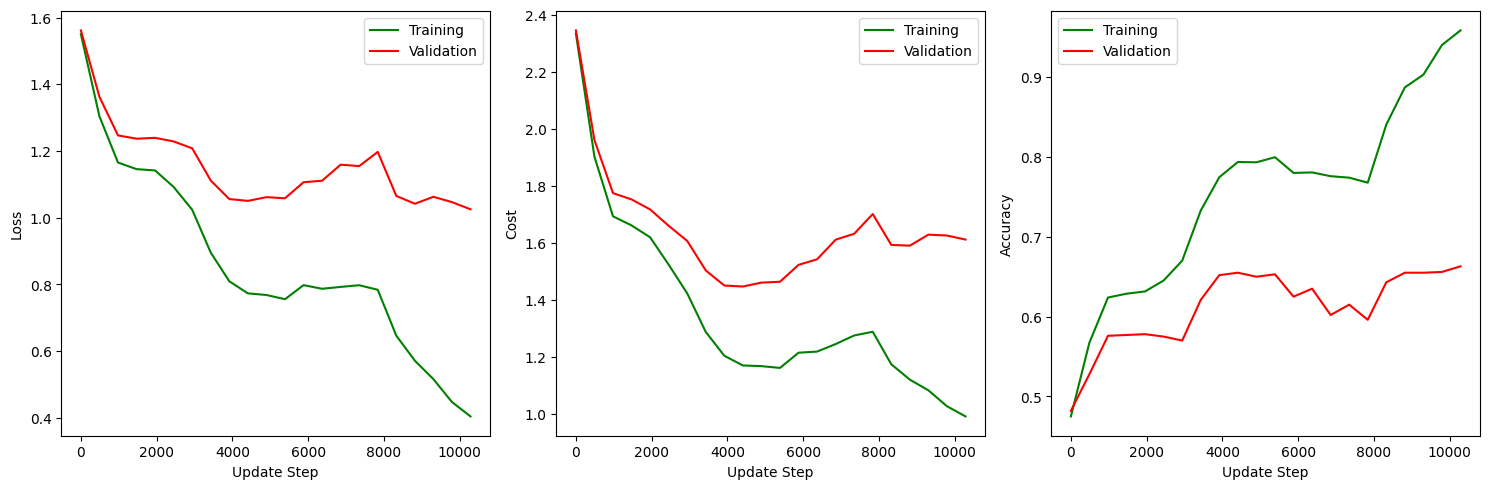

Filter size: 4, Num. filters: 40, Test acc: 0.6603, Training time: 348.42 (s)
Training using: f=4, n_f=40, m=300, lam=0.0025, label_smoothing=0.05...
Cycle 1/3, Train. Loss: 1.5206, Val. Loss: 1.5342, Train. Acc: 0.4777, Val. Acc: 0.4780
Cycle 1/3, Train. Loss: 1.2622, Val. Loss: 1.3284, Train. Acc: 0.5711, Val. Acc: 0.5210
Cycle 1/3, Train. Loss: 1.1097, Val. Loss: 1.2042, Train. Acc: 0.6303, Val. Acc: 0.5790
Cycle 2/3, Train. Loss: 1.0911, Val. Loss: 1.1967, Train. Acc: 0.6352, Val. Acc: 0.5850
Cycle 2/3, Train. Loss: 1.0783, Val. Loss: 1.1924, Train. Acc: 0.6406, Val. Acc: 0.5850
Cycle 2/3, Train. Loss: 1.0336, Val. Loss: 1.1920, Train. Acc: 0.6523, Val. Acc: 0.5750
Cycle 2/3, Train. Loss: 0.9667, Val. Loss: 1.1808, Train. Acc: 0.6786, Val. Acc: 0.5740
Cycle 2/3, Train. Loss: 0.8127, Val. Loss: 1.0703, Train. Acc: 0.7450, Val. Acc: 0.6260
Cycle 2/3, Train. Loss: 0.7171, Val. Loss: 1.0157, Train. Acc: 0.7896, Val. Acc: 0.6520
Cycle 3/3, Train. Loss: 0.6738, Val. Loss: 1.0074, Train. 

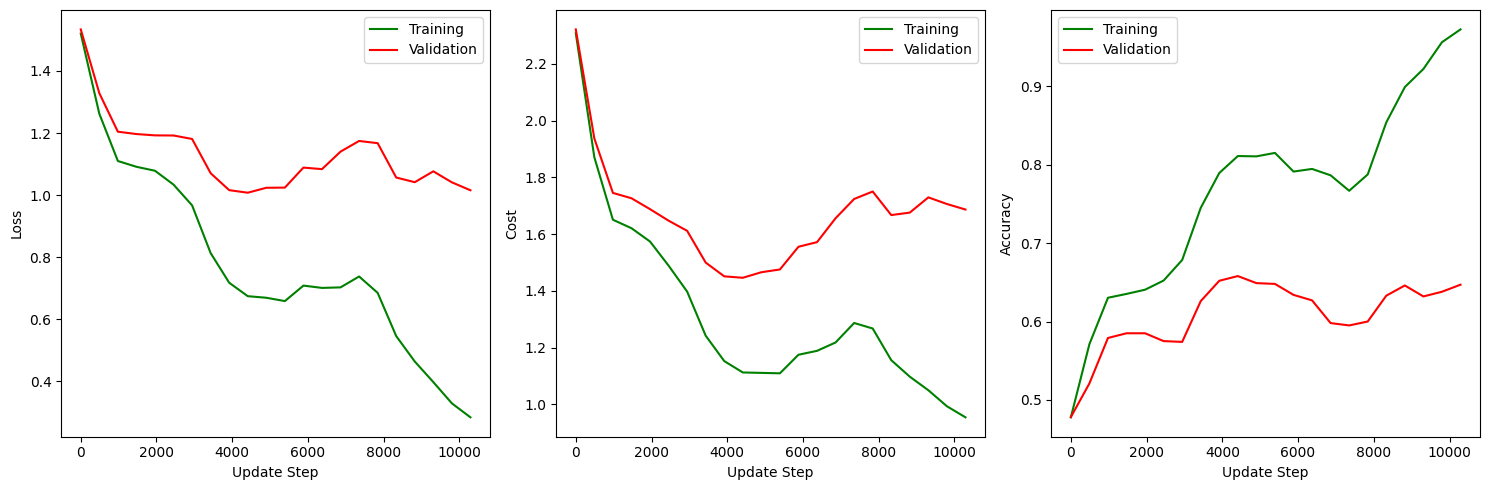

Filter size: 4, Num. filters: 40, Test acc: 0.6553, Training time: 344.45 (s)
Training using: f=4, n_f=40, m=300, lam=0.001, label_smoothing=0.1...
Cycle 1/3, Train. Loss: 1.5439, Val. Loss: 1.5562, Train. Acc: 0.4767, Val. Acc: 0.4830
Cycle 1/3, Train. Loss: 1.2848, Val. Loss: 1.3516, Train. Acc: 0.5741, Val. Acc: 0.5240
Cycle 1/3, Train. Loss: 1.1365, Val. Loss: 1.2335, Train. Acc: 0.6329, Val. Acc: 0.5840
Cycle 2/3, Train. Loss: 1.1119, Val. Loss: 1.2229, Train. Acc: 0.6396, Val. Acc: 0.5890
Cycle 2/3, Train. Loss: 1.0956, Val. Loss: 1.2191, Train. Acc: 0.6487, Val. Acc: 0.5860
Cycle 2/3, Train. Loss: 1.0300, Val. Loss: 1.2024, Train. Acc: 0.6692, Val. Acc: 0.5770
Cycle 2/3, Train. Loss: 0.9487, Val. Loss: 1.1963, Train. Acc: 0.6997, Val. Acc: 0.5750
Cycle 2/3, Train. Loss: 0.7899, Val. Loss: 1.0883, Train. Acc: 0.7786, Val. Acc: 0.6210
Cycle 2/3, Train. Loss: 0.6961, Val. Loss: 1.0446, Train. Acc: 0.8211, Val. Acc: 0.6470
Cycle 3/3, Train. Loss: 0.6611, Val. Loss: 1.0446, Train. Ac

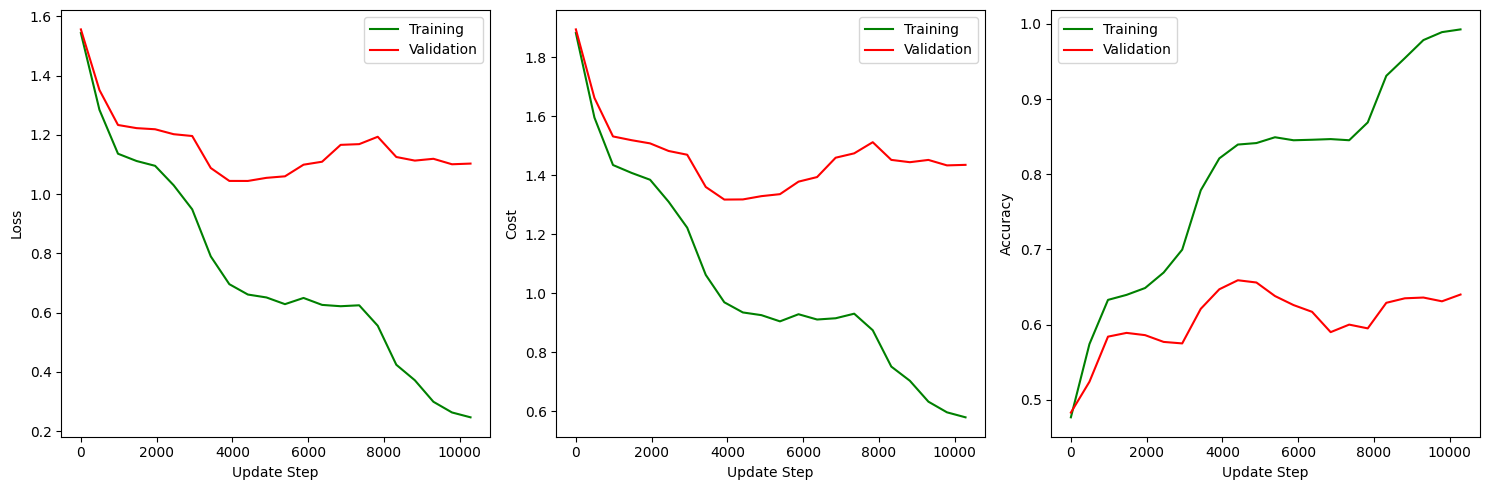

Filter size: 4, Num. filters: 40, Test acc: 0.6351, Training time: 348.81 (s)
Training using: f=4, n_f=40, m=300, lam=0.001, label_smoothing=0.05...
Cycle 1/3, Train. Loss: 1.5144, Val. Loss: 1.5295, Train. Acc: 0.4794, Val. Acc: 0.4820
Cycle 1/3, Train. Loss: 1.2404, Val. Loss: 1.3158, Train. Acc: 0.5768, Val. Acc: 0.5320
Cycle 1/3, Train. Loss: 1.0795, Val. Loss: 1.1915, Train. Acc: 0.6385, Val. Acc: 0.5860
Cycle 2/3, Train. Loss: 1.0572, Val. Loss: 1.1835, Train. Acc: 0.6458, Val. Acc: 0.5880
Cycle 2/3, Train. Loss: 1.0312, Val. Loss: 1.1706, Train. Acc: 0.6581, Val. Acc: 0.5910
Cycle 2/3, Train. Loss: 0.9639, Val. Loss: 1.1699, Train. Acc: 0.6798, Val. Acc: 0.5920
Cycle 2/3, Train. Loss: 0.8844, Val. Loss: 1.1780, Train. Acc: 0.7083, Val. Acc: 0.5730
Cycle 2/3, Train. Loss: 0.6991, Val. Loss: 1.0525, Train. Acc: 0.7924, Val. Acc: 0.6310
Cycle 2/3, Train. Loss: 0.5964, Val. Loss: 1.0202, Train. Acc: 0.8363, Val. Acc: 0.6530
Cycle 3/3, Train. Loss: 0.5539, Val. Loss: 1.0197, Train. A

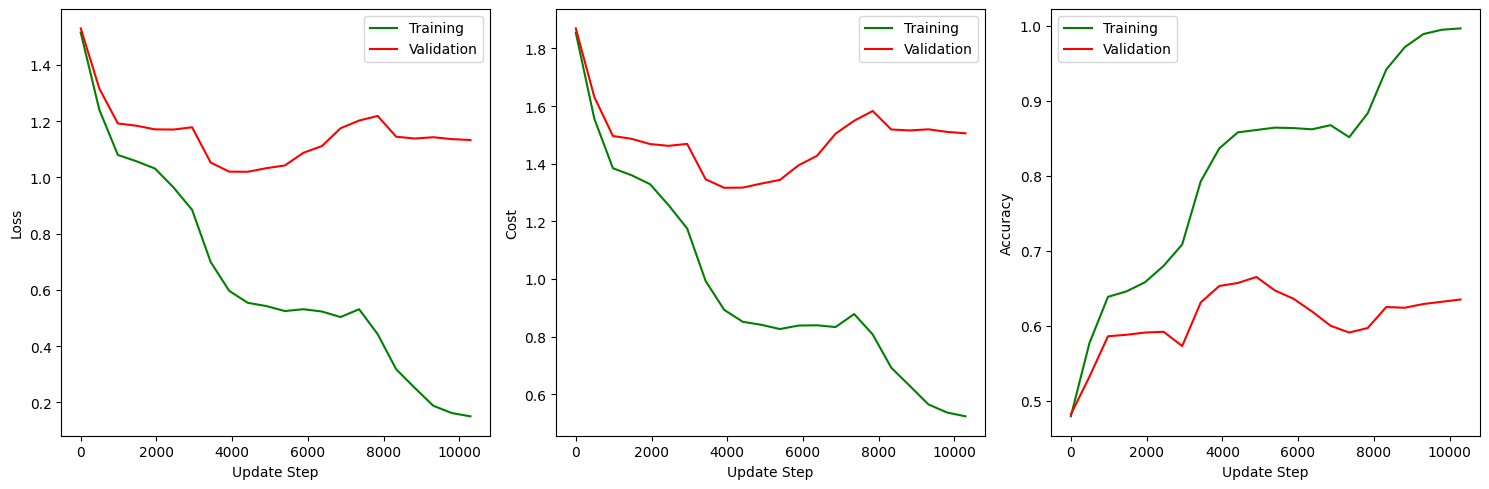

Filter size: 4, Num. filters: 40, Test acc: 0.6379, Training time: 344.87 (s)
Training using: f=4, n_f=40, m=300, lam=0.0001, label_smoothing=0.1...
Cycle 1/3, Train. Loss: 1.5406, Val. Loss: 1.5554, Train. Acc: 0.4783, Val. Acc: 0.4830
Cycle 1/3, Train. Loss: 1.2724, Val. Loss: 1.3437, Train. Acc: 0.5767, Val. Acc: 0.5260
Cycle 1/3, Train. Loss: 1.1173, Val. Loss: 1.2239, Train. Acc: 0.6386, Val. Acc: 0.5840
Cycle 2/3, Train. Loss: 1.0913, Val. Loss: 1.2147, Train. Acc: 0.6471, Val. Acc: 0.5860
Cycle 2/3, Train. Loss: 1.0629, Val. Loss: 1.2074, Train. Acc: 0.6598, Val. Acc: 0.5840
Cycle 2/3, Train. Loss: 0.9928, Val. Loss: 1.1962, Train. Acc: 0.6856, Val. Acc: 0.5850
Cycle 2/3, Train. Loss: 0.8920, Val. Loss: 1.1872, Train. Acc: 0.7224, Val. Acc: 0.5790
Cycle 2/3, Train. Loss: 0.7235, Val. Loss: 1.0900, Train. Acc: 0.8069, Val. Acc: 0.6250
Cycle 2/3, Train. Loss: 0.6275, Val. Loss: 1.0549, Train. Acc: 0.8483, Val. Acc: 0.6460
Cycle 3/3, Train. Loss: 0.5933, Val. Loss: 1.0604, Train. A

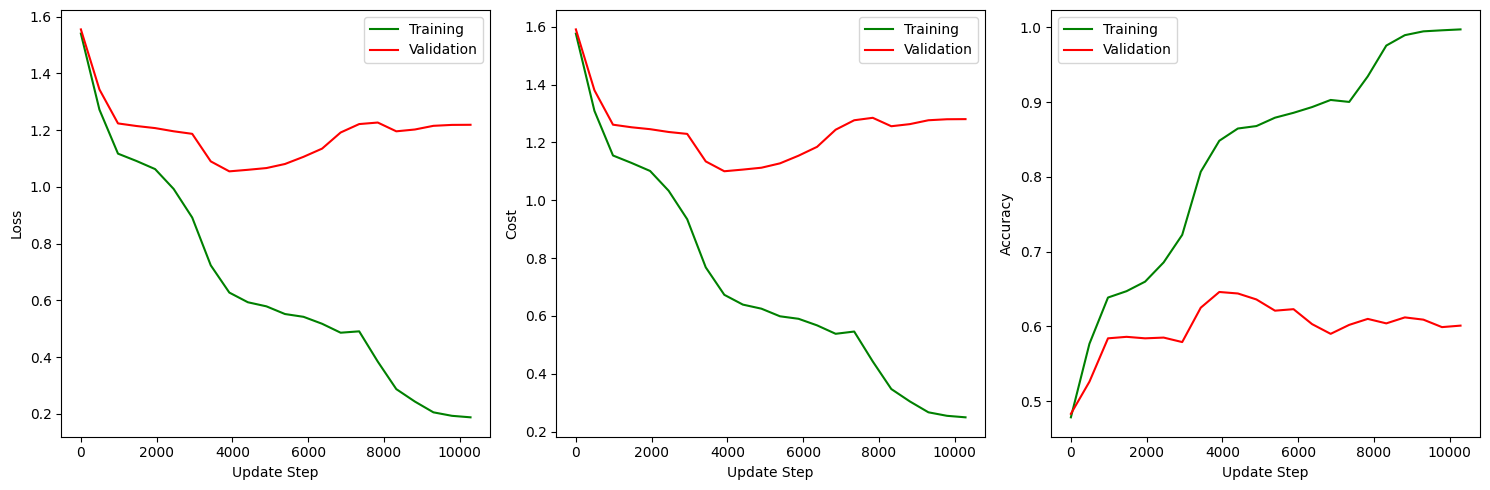

Filter size: 4, Num. filters: 40, Test acc: 0.6040, Training time: 344.41 (s)
Training using: f=4, n_f=40, m=300, lam=0.0001, label_smoothing=0.05...
Cycle 1/3, Train. Loss: 1.5123, Val. Loss: 1.5253, Train. Acc: 0.4798, Val. Acc: 0.4830
Cycle 1/3, Train. Loss: 1.2320, Val. Loss: 1.3131, Train. Acc: 0.5801, Val. Acc: 0.5350
Cycle 1/3, Train. Loss: 1.0623, Val. Loss: 1.1847, Train. Acc: 0.6446, Val. Acc: 0.5850
Cycle 2/3, Train. Loss: 1.0361, Val. Loss: 1.1752, Train. Acc: 0.6524, Val. Acc: 0.5940
Cycle 2/3, Train. Loss: 1.0049, Val. Loss: 1.1702, Train. Acc: 0.6657, Val. Acc: 0.5810
Cycle 2/3, Train. Loss: 0.9286, Val. Loss: 1.1660, Train. Acc: 0.6928, Val. Acc: 0.5880
Cycle 2/3, Train. Loss: 0.8230, Val. Loss: 1.1734, Train. Acc: 0.7340, Val. Acc: 0.5800
Cycle 2/3, Train. Loss: 0.6296, Val. Loss: 1.0603, Train. Acc: 0.8218, Val. Acc: 0.6310
Cycle 2/3, Train. Loss: 0.5217, Val. Loss: 1.0344, Train. Acc: 0.8640, Val. Acc: 0.6470
Cycle 3/3, Train. Loss: 0.4829, Val. Loss: 1.0433, Train. 

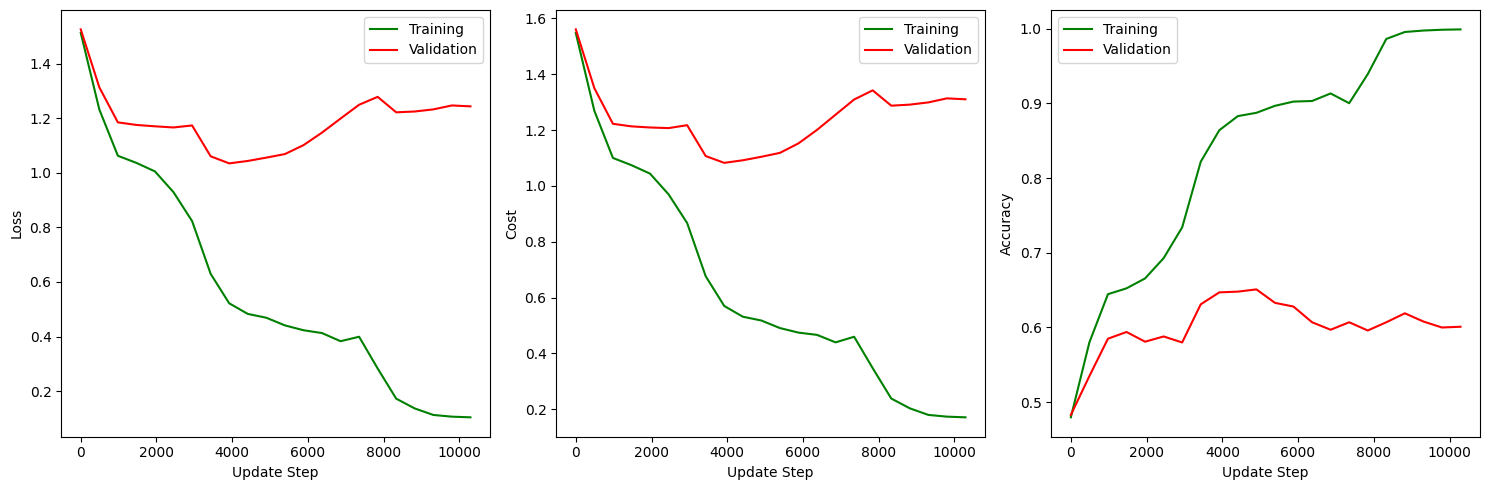

Filter size: 4, Num. filters: 40, Test acc: 0.6081, Training time: 346.50 (s)


In [56]:
import time

explore_params = [
    {'f': 4, 'n_f': 40, 'm': 300, 'lam': 0.0025, 'label_smoothing': 0.1},
    {'f': 4, 'n_f': 40, 'm': 300, 'lam': 0.0025, 'label_smoothing': 0.05},
    {'f': 4, 'n_f': 40, 'm': 300, 'lam': 0.001, 'label_smoothing': 0.1},
    {'f': 4, 'n_f': 40, 'm': 300, 'lam': 0.001, 'label_smoothing': 0.05},
    {'f': 4, 'n_f': 40, 'm': 300, 'lam': 0.0001, 'label_smoothing': 0.1},
    {'f': 4, 'n_f': 40, 'm': 300, 'lam': 0.0001, 'label_smoothing': 0.05},
]
performance_results = []
training_times = []

for params in explore_params:
    f = params['f']
    n_f = params['n_f']
    m = params['m']
    lam = params['lam']
    GDparams = {
        'n_batch': 100,
    }

    # Note that we must keep this in the loop as mini_batch_gd
    # will be updating the step sizes and we want to have the same
    # starting point for each combination of parameters.
    cyclical_lr = {
        'eta_min': 1e-5,
        'eta_max': 1e-1,
        'n_s': 800, # step size for cyclical learning rate
        'increasing_step_sizes': True,
        'cycles': 3
    }

    lam = params['lam']

    print(f"Training using: f={f}, n_f={n_f}, m={m}, lam={lam}, label_smoothing={params['label_smoothing']}...")

    rng = np.random.default_rng(42)

    net = NeuralNetwork()
    net.add_layer([
        ConvolutionalLayer(f=f, n_f=n_f, activation="relu", lam=lam),
        FlattenLayer(),
        FullyConnectedLayer(d=(32//f)*(32//f)*n_f, m=m, activation="relu", lam=lam),
        FullyConnectedLayer(d=m, m=NUM_CLASSES, activation="softmax", lam=lam),
    ])

    start_time = time.time()
    net.cyclic_mini_batch_gd(rng, net.compute_loss, net.compute_cost, data, GDparams, cyclical_lr, verbose=2, label_smoothing=params['label_smoothing'])
    end_time = time.time()

    acc = net.compute_acc(net.apply_network(data.X_test), data.y_test)

    performance_results.append(acc)
    training_times.append(end_time - start_time)

    print(f"Filter size: {f}, Num. filters: {n_f}, Test acc: {acc:.4f}, Training time: {end_time - start_time:.2f} (s)")

Training using: f=4, n_f=40, m=300, lam=0.0025, label_smoothing=0.0...
Cycle 1/3, Train. Loss: 1.4997, Val. Loss: 1.5136, Train. Acc: 0.4783, Val. Acc: 0.4700
Cycle 1/3, Train. Loss: 1.2301, Val. Loss: 1.3073, Train. Acc: 0.5726, Val. Acc: 0.5340
Cycle 1/3, Train. Loss: 1.0630, Val. Loss: 1.1753, Train. Acc: 0.6344, Val. Acc: 0.5870
Cycle 2/3, Train. Loss: 1.0450, Val. Loss: 1.1704, Train. Acc: 0.6400, Val. Acc: 0.5850
Cycle 2/3, Train. Loss: 1.0238, Val. Loss: 1.1630, Train. Acc: 0.6479, Val. Acc: 0.5910
Cycle 2/3, Train. Loss: 0.9897, Val. Loss: 1.1834, Train. Acc: 0.6552, Val. Acc: 0.5740
Cycle 2/3, Train. Loss: 0.9117, Val. Loss: 1.1807, Train. Acc: 0.6836, Val. Acc: 0.5700
Cycle 2/3, Train. Loss: 0.7365, Val. Loss: 1.0598, Train. Acc: 0.7547, Val. Acc: 0.6210
Cycle 2/3, Train. Loss: 0.6237, Val. Loss: 1.0037, Train. Acc: 0.8022, Val. Acc: 0.6570
Cycle 3/3, Train. Loss: 0.5708, Val. Loss: 0.9993, Train. Acc: 0.8276, Val. Acc: 0.6550
Cycle 3/3, Train. Loss: 0.5650, Val. Loss: 1.0244

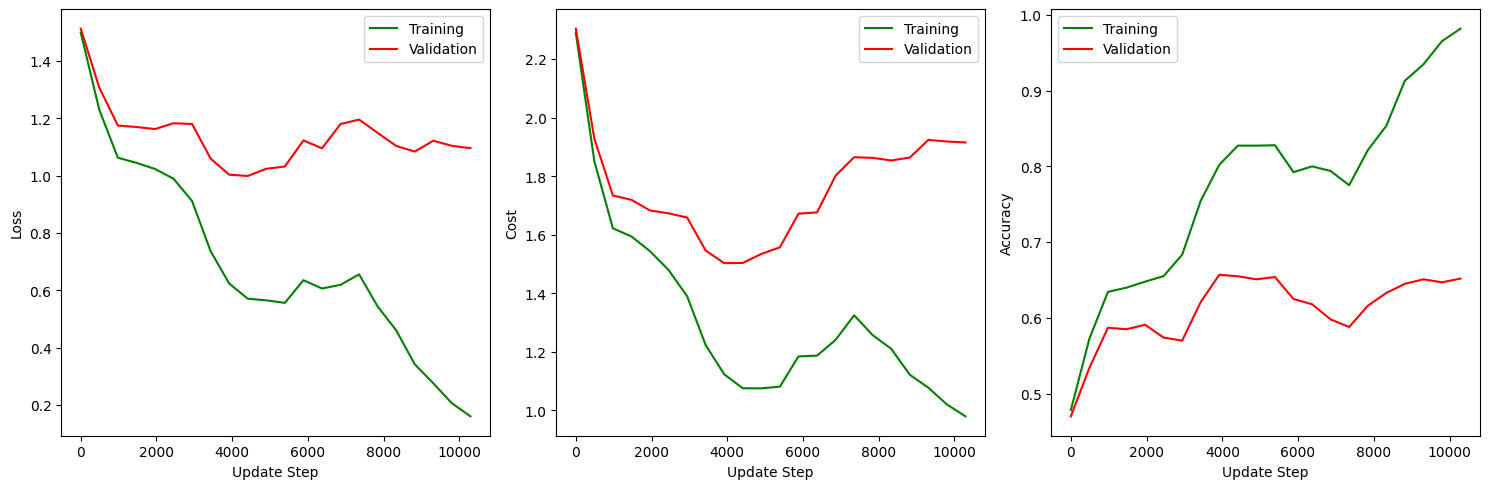

Filter size: 4, Num. filters: 40, Test acc: 0.6579, Training time: 350.76 (s)
Training using: f=4, n_f=40, m=300, lam=0.0025, label_smoothing=0.05...
Cycle 1/3, Train. Loss: 1.5206, Val. Loss: 1.5342, Train. Acc: 0.4777, Val. Acc: 0.4780
Cycle 1/3, Train. Loss: 1.2622, Val. Loss: 1.3284, Train. Acc: 0.5711, Val. Acc: 0.5210
Cycle 1/3, Train. Loss: 1.1097, Val. Loss: 1.2042, Train. Acc: 0.6303, Val. Acc: 0.5790
Cycle 2/3, Train. Loss: 1.0911, Val. Loss: 1.1967, Train. Acc: 0.6352, Val. Acc: 0.5850
Cycle 2/3, Train. Loss: 1.0783, Val. Loss: 1.1924, Train. Acc: 0.6406, Val. Acc: 0.5850
Cycle 2/3, Train. Loss: 1.0336, Val. Loss: 1.1920, Train. Acc: 0.6523, Val. Acc: 0.5750
Cycle 2/3, Train. Loss: 0.9667, Val. Loss: 1.1808, Train. Acc: 0.6786, Val. Acc: 0.5740
Cycle 2/3, Train. Loss: 0.8127, Val. Loss: 1.0703, Train. Acc: 0.7450, Val. Acc: 0.6260
Cycle 2/3, Train. Loss: 0.7171, Val. Loss: 1.0157, Train. Acc: 0.7896, Val. Acc: 0.6520
Cycle 3/3, Train. Loss: 0.6738, Val. Loss: 1.0074, Train. 

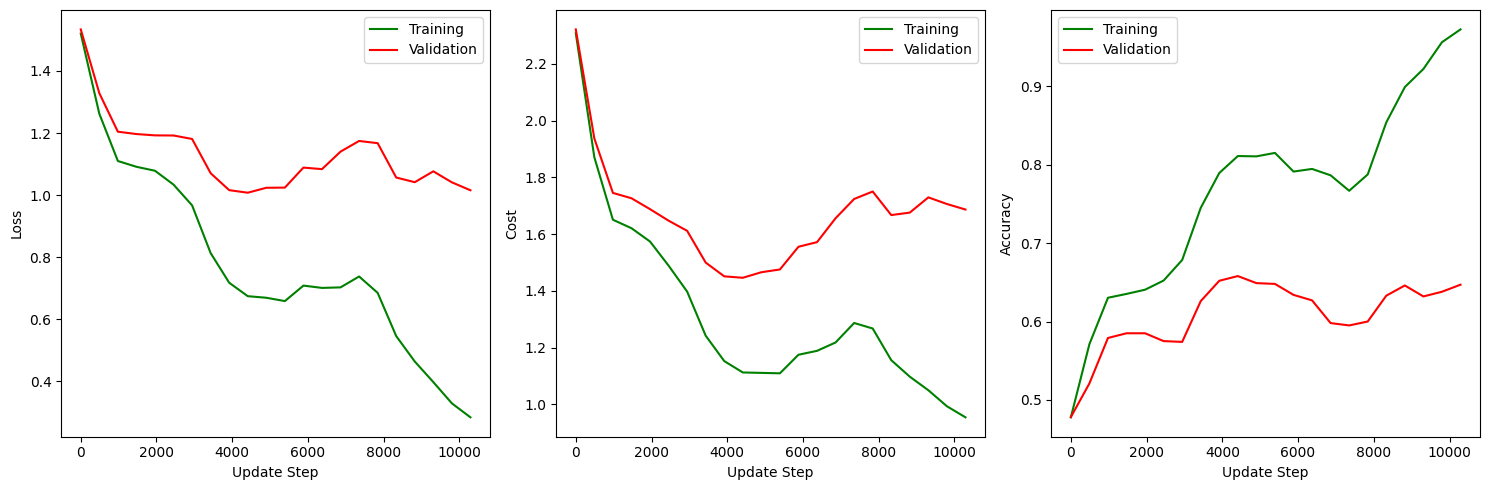

Filter size: 4, Num. filters: 40, Test acc: 0.6553, Training time: 348.23 (s)


In [ ]:
import time


explore_params = [
    {'f': 4, 'n_f': 40, 'm': 300, 'lam': 0.0025, 'label_smoothing': 0.00},
    {'f': 4, 'n_f': 40, 'm': 300, 'lam': 0.0025, 'label_smoothing': 0.05},
]
performance_results = []
training_times = []

for params in explore_params:
    f = params['f']
    n_f = params['n_f']
    m = params['m']
    lam = params['lam']
    GDparams = {
        'n_batch': 100,
    }

    # Note that we must keep this in the loop as mini_batch_gd
    # will be updating the step sizes and we want to have the same
    # starting point for each combination of parameters.
    cyclical_lr = {
        'eta_min': 1e-5,
        'eta_max': 1e-1,
        'n_s': 800, # step size for cyclical learning rate
        'increasing_step_sizes': True,
        'cycles': 3
    }

    lam = params['lam']

    print(f"Training using: f={f}, n_f={n_f}, m={m}, lam={lam}, label_smoothing={params['label_smoothing']}...")

    rng = np.random.default_rng(42)

    net = NeuralNetwork()
    net.add_layer([
        ConvolutionalLayer(f=f, n_f=n_f, activation="relu", lam=lam),
        FlattenLayer(),
        FullyConnectedLayer(d=(32//f)*(32//f)*n_f, m=m, activation="relu", lam=lam),
        FullyConnectedLayer(d=m, m=NUM_CLASSES, activation="softmax", lam=lam),
    ])

    start_time = time.time()
    net.cyclic_mini_batch_gd(rng, net.compute_loss, net.compute_cost, data, GDparams, cyclical_lr, verbose=2, label_smoothing=params['label_smoothing'])
    end_time = time.time()

    acc = net.compute_acc(net.apply_network(data.X_test), data.y_test)

    performance_results.append(acc)
    training_times.append(end_time - start_time)

    print(f"Filter size: {f}, Num. filters: {n_f}, Test acc: {acc:.4f}, Training time: {end_time - start_time:.2f} (s)")

Training using: f=4, n_f=40, m=300, lam=0.0025, label_smoothing=0.1...
Cycle 1/3, Train. Loss: 1.5501, Val. Loss: 1.5614, Train. Acc: 0.4750, Val. Acc: 0.4820
Cycle 1/3, Train. Loss: 1.3038, Val. Loss: 1.3622, Train. Acc: 0.5675, Val. Acc: 0.5280
Cycle 1/3, Train. Loss: 1.1653, Val. Loss: 1.2467, Train. Acc: 0.6239, Val. Acc: 0.5760
Cycle 2/3, Train. Loss: 1.1456, Val. Loss: 1.2368, Train. Acc: 0.6287, Val. Acc: 0.5770
Cycle 2/3, Train. Loss: 1.1417, Val. Loss: 1.2394, Train. Acc: 0.6316, Val. Acc: 0.5780
Cycle 2/3, Train. Loss: 1.0922, Val. Loss: 1.2286, Train. Acc: 0.6452, Val. Acc: 0.5750
Cycle 2/3, Train. Loss: 1.0238, Val. Loss: 1.2079, Train. Acc: 0.6701, Val. Acc: 0.5700
Cycle 2/3, Train. Loss: 0.8955, Val. Loss: 1.1114, Train. Acc: 0.7329, Val. Acc: 0.6210
Cycle 2/3, Train. Loss: 0.8095, Val. Loss: 1.0560, Train. Acc: 0.7746, Val. Acc: 0.6520
Cycle 3/3, Train. Loss: 0.7734, Val. Loss: 1.0505, Train. Acc: 0.7937, Val. Acc: 0.6550
Cycle 3/3, Train. Loss: 0.7685, Val. Loss: 1.0616

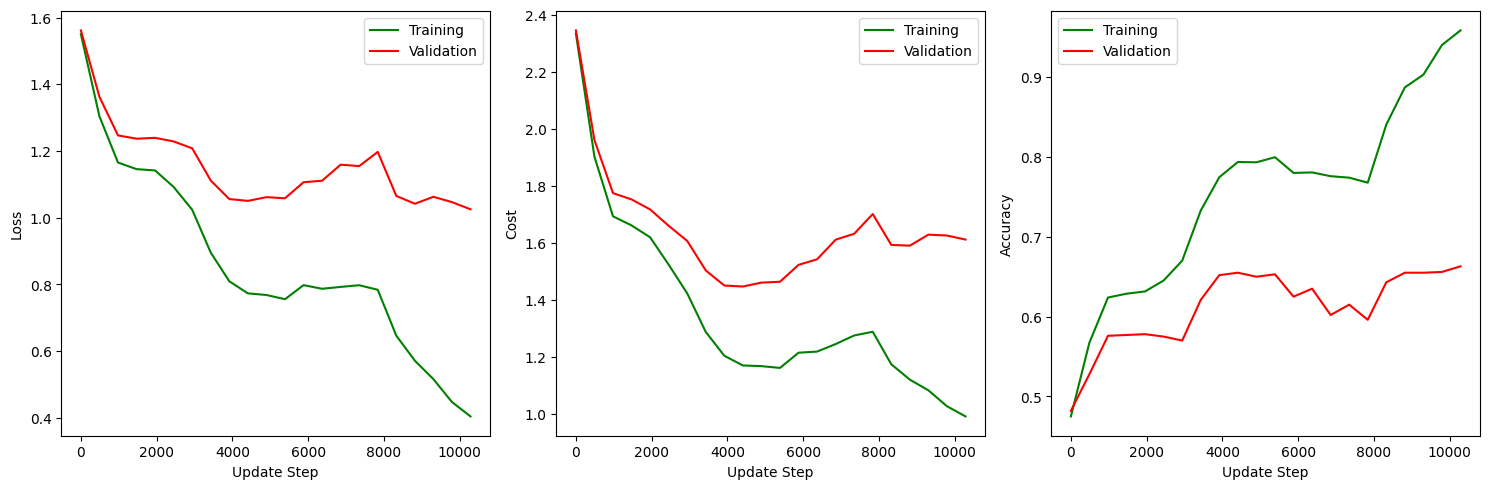

Filter size: 4, Num. filters: 40, Test acc: 0.6603, Training time: 343.56 (s)


In [19]:
import time


explore_params = [
    {'f': 4, 'n_f': 40, 'm': 300, 'lam': 0.0025, 'label_smoothing': 0.1},
]
performance_results = []
training_times = []

for params in explore_params:
    f = params['f']
    n_f = params['n_f']
    m = params['m']
    lam = params['lam']
    GDparams = {
        'n_batch': 100,
    }

    # Note that we must keep this in the loop as mini_batch_gd
    # will be updating the step sizes and we want to have the same
    # starting point for each combination of parameters.
    cyclical_lr = {
        'eta_min': 1e-5,
        'eta_max': 1e-1,
        'n_s': 800, # step size for cyclical learning rate
        'increasing_step_sizes': True,
        'cycles': 3
    }

    lam = params['lam']

    print(f"Training using: f={f}, n_f={n_f}, m={m}, lam={lam}, label_smoothing={params['label_smoothing']}...")

    rng = np.random.default_rng(42)

    net = NeuralNetwork()
    net.add_layer([
        ConvolutionalLayer(f=f, n_f=n_f, activation="relu", lam=lam),
        FlattenLayer(),
        FullyConnectedLayer(d=(32//f)*(32//f)*n_f, m=m, activation="relu", lam=lam),
        FullyConnectedLayer(d=m, m=NUM_CLASSES, activation="softmax", lam=lam),
    ])

    start_time = time.time()
    net.cyclic_mini_batch_gd(rng, net.compute_loss, net.compute_cost, data, GDparams, cyclical_lr, verbose=2, label_smoothing=params['label_smoothing'])
    end_time = time.time()

    acc = net.compute_acc(net.apply_network(data.X_test), data.y_test)

    performance_results.append(acc)
    training_times.append(end_time - start_time)

    print(f"Filter size: {f}, Num. filters: {n_f}, Test acc: {acc:.4f}, Training time: {end_time - start_time:.2f} (s)")

Training using: f=4, n_f=40, m=300, lam=0, label_smoothing=0.0...
Cycle 1/3, Train. Loss: 1.4885, Val. Loss: 1.5064, Train. Acc: 0.4821, Val. Acc: 0.4760
Cycle 1/3, Train. Loss: 1.1995, Val. Loss: 1.2893, Train. Acc: 0.5838, Val. Acc: 0.5360
Cycle 1/3, Train. Loss: 1.0130, Val. Loss: 1.1563, Train. Acc: 0.6514, Val. Acc: 0.5850
Cycle 2/3, Train. Loss: 0.9871, Val. Loss: 1.1526, Train. Acc: 0.6591, Val. Acc: 0.5930
Cycle 2/3, Train. Loss: 0.9457, Val. Loss: 1.1442, Train. Acc: 0.6743, Val. Acc: 0.5920
Cycle 2/3, Train. Loss: 0.8716, Val. Loss: 1.1641, Train. Acc: 0.6993, Val. Acc: 0.5930
Cycle 2/3, Train. Loss: 0.7549, Val. Loss: 1.1895, Train. Acc: 0.7402, Val. Acc: 0.5810
Cycle 2/3, Train. Loss: 0.5274, Val. Loss: 1.0805, Train. Acc: 0.8350, Val. Acc: 0.6270
Cycle 2/3, Train. Loss: 0.4036, Val. Loss: 1.0975, Train. Acc: 0.8822, Val. Acc: 0.6450
Cycle 3/3, Train. Loss: 0.3580, Val. Loss: 1.1216, Train. Acc: 0.9017, Val. Acc: 0.6420
Cycle 3/3, Train. Loss: 0.3451, Val. Loss: 1.1551, Tra

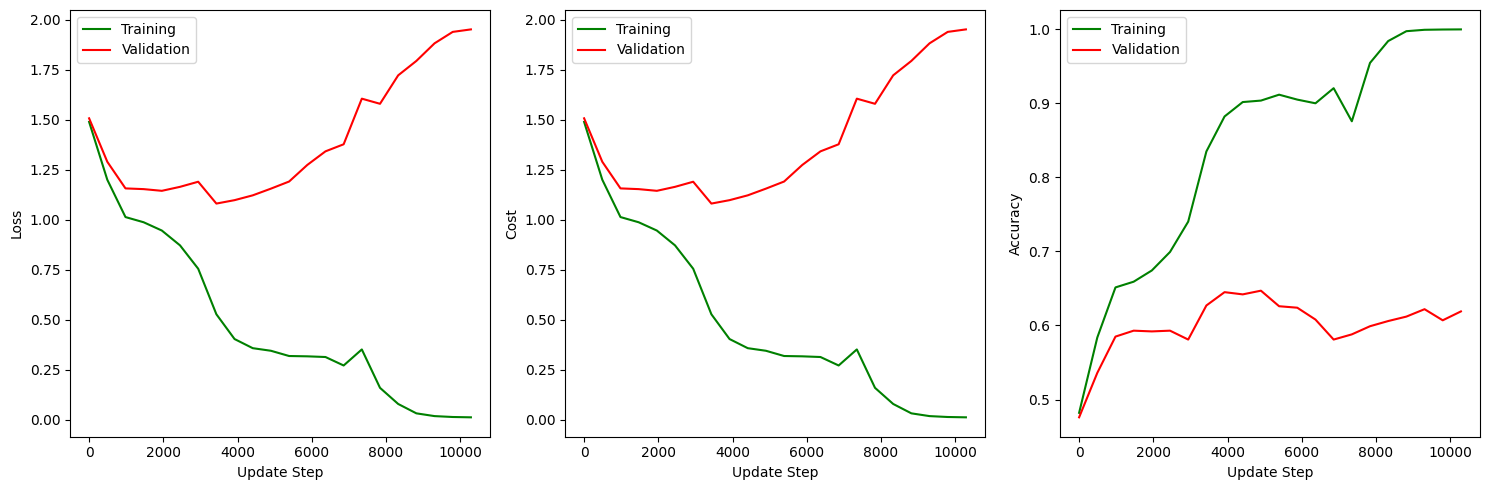

Filter size: 4, Num. filters: 40, Test acc: 0.6252, Training time: 337.84 (s)
Training using: f=4, n_f=40, m=300, lam=0, label_smoothing=0.1...
Cycle 1/3, Train. Loss: 1.5417, Val. Loss: 1.5530, Train. Acc: 0.4771, Val. Acc: 0.4810
Cycle 1/3, Train. Loss: 1.2683, Val. Loss: 1.3380, Train. Acc: 0.5778, Val. Acc: 0.5300
Cycle 1/3, Train. Loss: 1.1158, Val. Loss: 1.2228, Train. Acc: 0.6384, Val. Acc: 0.5850
Cycle 2/3, Train. Loss: 1.0896, Val. Loss: 1.2110, Train. Acc: 0.6469, Val. Acc: 0.5890
Cycle 2/3, Train. Loss: 1.0622, Val. Loss: 1.2039, Train. Acc: 0.6607, Val. Acc: 0.5810
Cycle 2/3, Train. Loss: 0.9897, Val. Loss: 1.1893, Train. Acc: 0.6860, Val. Acc: 0.5960
Cycle 2/3, Train. Loss: 0.8866, Val. Loss: 1.1797, Train. Acc: 0.7248, Val. Acc: 0.5990
Cycle 2/3, Train. Loss: 0.7182, Val. Loss: 1.0843, Train. Acc: 0.8082, Val. Acc: 0.6340
Cycle 2/3, Train. Loss: 0.6233, Val. Loss: 1.0536, Train. Acc: 0.8499, Val. Acc: 0.6470
Cycle 3/3, Train. Loss: 0.5893, Val. Loss: 1.0593, Train. Acc: 0

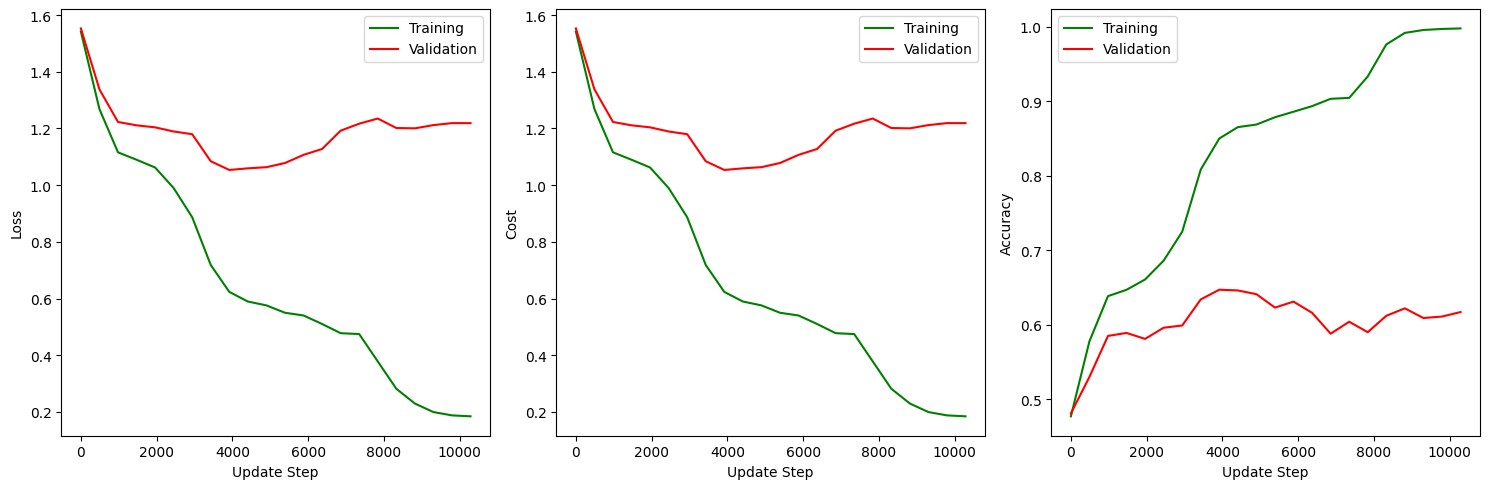

Filter size: 4, Num. filters: 40, Test acc: 0.6038, Training time: 334.96 (s)


In [20]:
import time


explore_params = [
    {'f': 4, 'n_f': 40, 'm': 300, 'lam': 0, 'label_smoothing': 0.00},
    {'f': 4, 'n_f': 40, 'm': 300, 'lam': 0, 'label_smoothing': 0.1},
]
performance_results = []
training_times = []

for params in explore_params:
    f = params['f']
    n_f = params['n_f']
    m = params['m']
    lam = params['lam']
    GDparams = {
        'n_batch': 100,
    }

    # Note that we must keep this in the loop as mini_batch_gd
    # will be updating the step sizes and we want to have the same
    # starting point for each combination of parameters.
    cyclical_lr = {
        'eta_min': 1e-5,
        'eta_max': 1e-1,
        'n_s': 800, # step size for cyclical learning rate
        'increasing_step_sizes': True,
        'cycles': 3
    }

    lam = params['lam']

    print(f"Training using: f={f}, n_f={n_f}, m={m}, lam={lam}, label_smoothing={params['label_smoothing']}...")

    rng = np.random.default_rng(42)

    net = NeuralNetwork()
    net.add_layer([
        ConvolutionalLayer(f=f, n_f=n_f, activation="relu", lam=lam),
        FlattenLayer(),
        FullyConnectedLayer(d=(32//f)*(32//f)*n_f, m=m, activation="relu", lam=lam),
        FullyConnectedLayer(d=m, m=NUM_CLASSES, activation="softmax", lam=lam),
    ])

    start_time = time.time()
    net.cyclic_mini_batch_gd(rng, net.compute_loss, net.compute_cost, data, GDparams, cyclical_lr, verbose=2, label_smoothing=params['label_smoothing'])
    end_time = time.time()

    acc = net.compute_acc(net.apply_network(data.X_test), data.y_test)

    performance_results.append(acc)
    training_times.append(end_time - start_time)

    print(f"Filter size: {f}, Num. filters: {n_f}, Test acc: {acc:.4f}, Training time: {end_time - start_time:.2f} (s)")

Training using: m=256, lam=0.0001, label_smoothing=0.025
Cycle 1/1, Train. Loss: 1.5049, Val. Loss: 1.5406, Train. Acc: 0.4765, Val. Acc: 0.4520
Cycle 1/1, Train. Loss: 1.2247, Val. Loss: 1.3023, Train. Acc: 0.5759, Val. Acc: 0.5440
Cycle 1/1, Train. Loss: 1.0387, Val. Loss: 1.1772, Train. Acc: 0.6478, Val. Acc: 0.5990


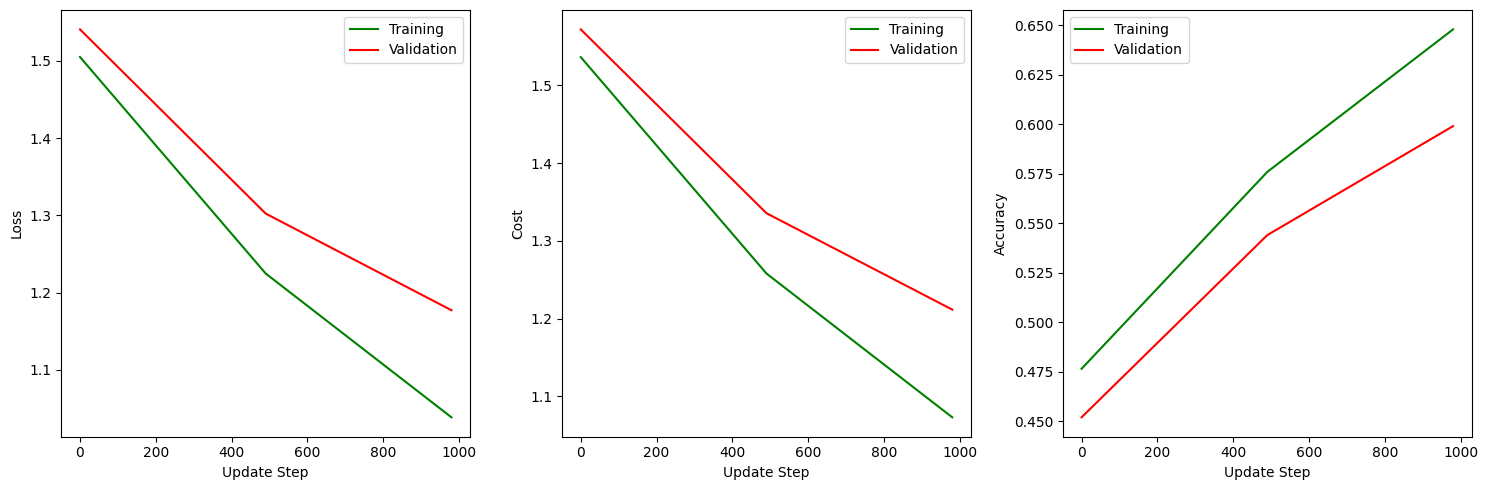

Filter size: 4, Num. filters: 40, Test acc: 0.5872, Training time: 47.54 (s), Label smoothing: 0.025
Training using: m=256, lam=0.0001, label_smoothing=0.05
Cycle 1/1, Train. Loss: 1.5182, Val. Loss: 1.5537, Train. Acc: 0.4754, Val. Acc: 0.4510
Cycle 1/1, Train. Loss: 1.2427, Val. Loss: 1.3101, Train. Acc: 0.5752, Val. Acc: 0.5410
Cycle 1/1, Train. Loss: 1.0647, Val. Loss: 1.1937, Train. Acc: 0.6452, Val. Acc: 0.5950


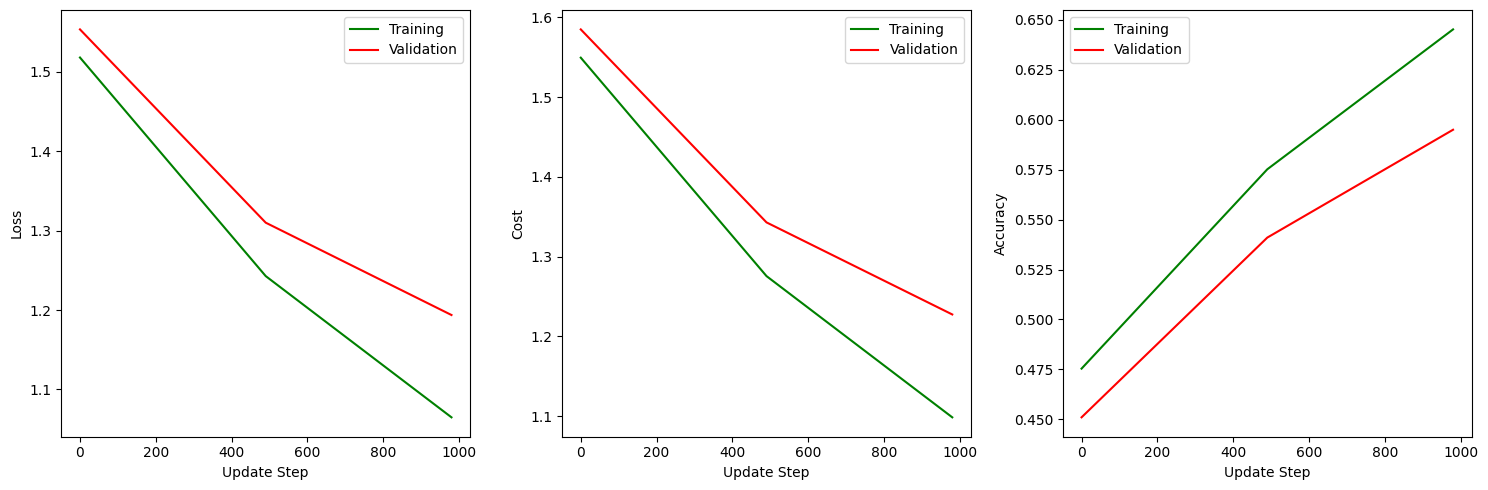

Filter size: 4, Num. filters: 40, Test acc: 0.5844, Training time: 47.32 (s), Label smoothing: 0.05
Training using: m=256, lam=0.0001, label_smoothing=0.1
Cycle 1/1, Train. Loss: 1.5490, Val. Loss: 1.5797, Train. Acc: 0.4732, Val. Acc: 0.4520
Cycle 1/1, Train. Loss: 1.2793, Val. Loss: 1.3415, Train. Acc: 0.5724, Val. Acc: 0.5330
Cycle 1/1, Train. Loss: 1.1222, Val. Loss: 1.2355, Train. Acc: 0.6391, Val. Acc: 0.5950


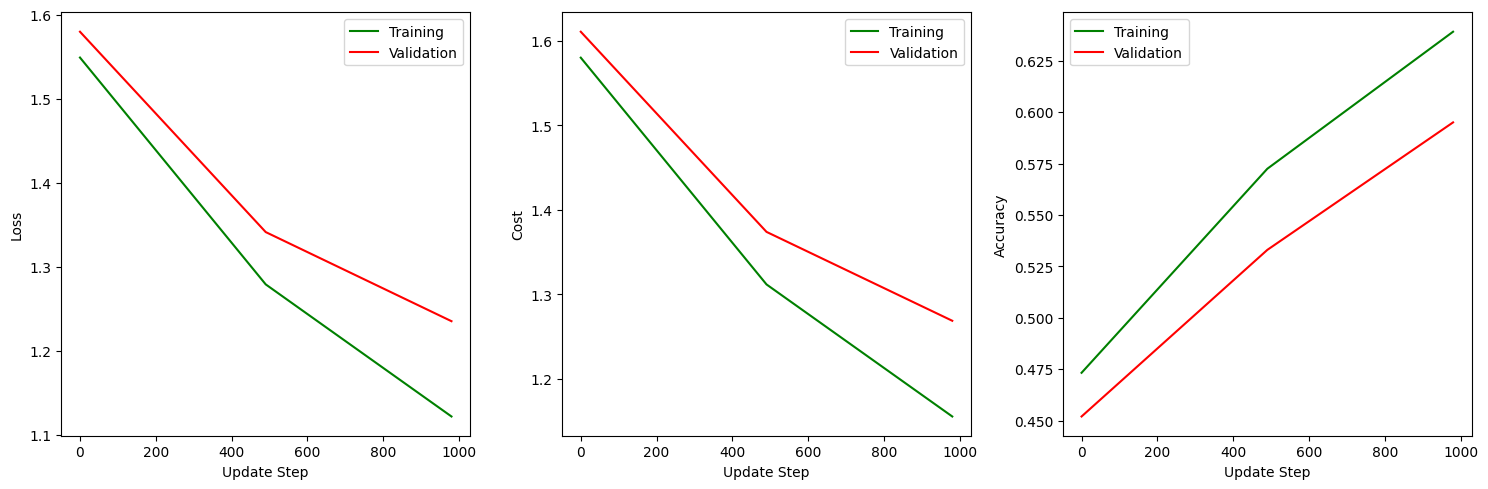

Filter size: 4, Num. filters: 40, Test acc: 0.5816, Training time: 46.73 (s), Label smoothing: 0.1
Training using: m=256, lam=0.001, label_smoothing=0.025
Cycle 1/1, Train. Loss: 1.5078, Val. Loss: 1.5422, Train. Acc: 0.4765, Val. Acc: 0.4530
Cycle 1/1, Train. Loss: 1.2380, Val. Loss: 1.3065, Train. Acc: 0.5709, Val. Acc: 0.5300
Cycle 1/1, Train. Loss: 1.0566, Val. Loss: 1.1851, Train. Acc: 0.6431, Val. Acc: 0.5960


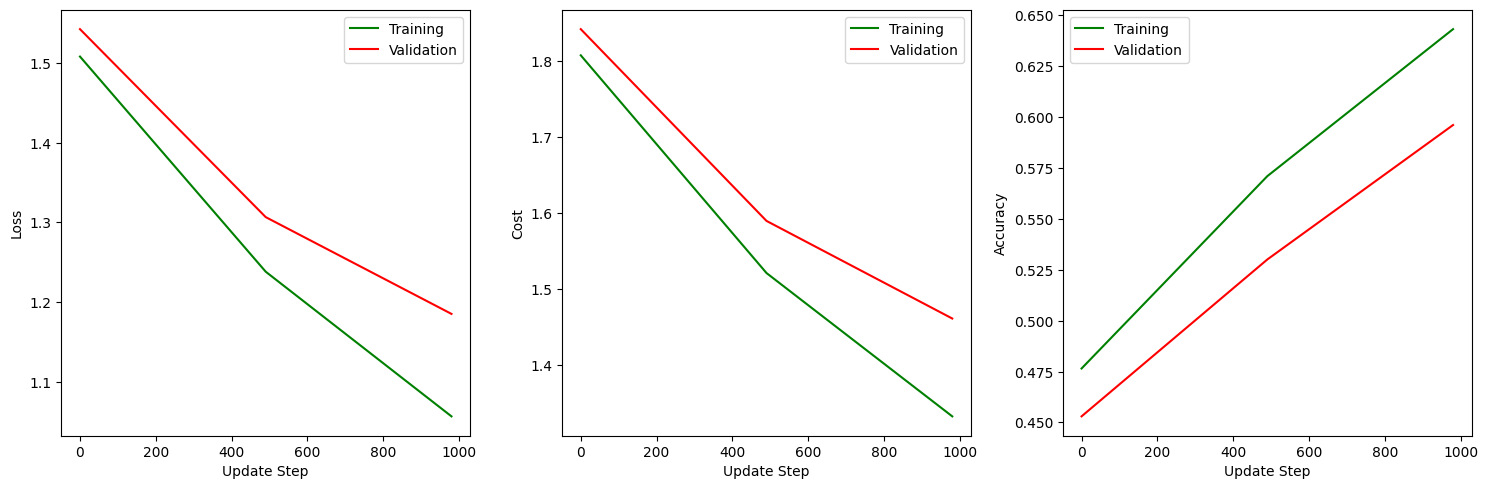

Filter size: 4, Num. filters: 40, Test acc: 0.5878, Training time: 46.97 (s), Label smoothing: 0.025
Training using: m=256, lam=0.001, label_smoothing=0.05
Cycle 1/1, Train. Loss: 1.5221, Val. Loss: 1.5564, Train. Acc: 0.4745, Val. Acc: 0.4500
Cycle 1/1, Train. Loss: 1.2523, Val. Loss: 1.3159, Train. Acc: 0.5696, Val. Acc: 0.5330
Cycle 1/1, Train. Loss: 1.0834, Val. Loss: 1.2033, Train. Acc: 0.6386, Val. Acc: 0.5920


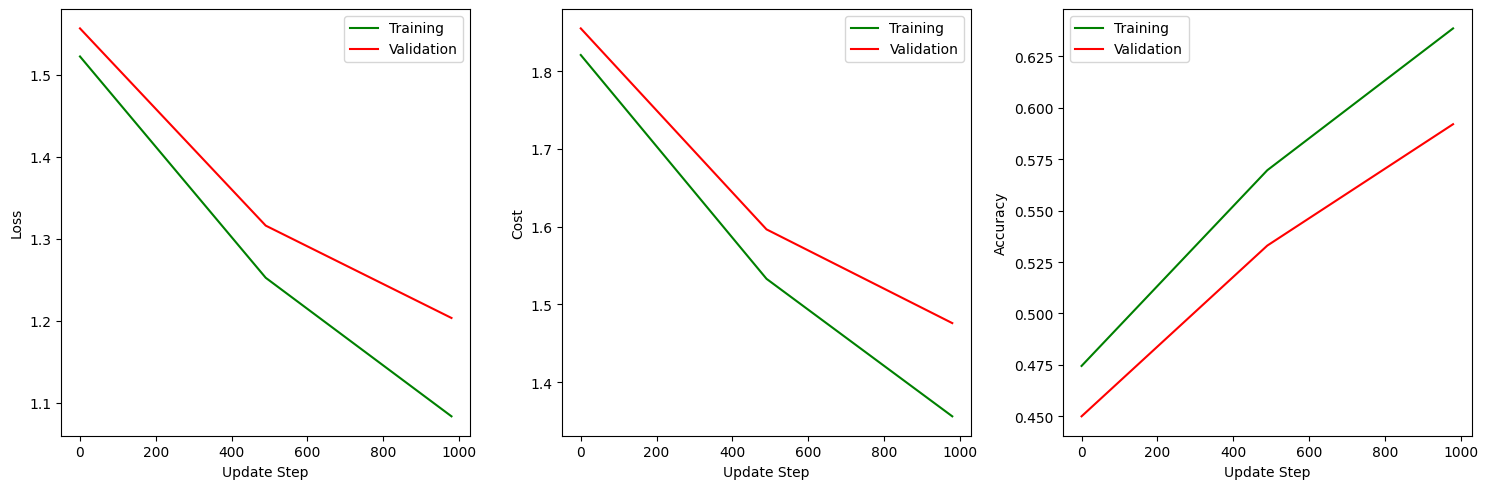

Filter size: 4, Num. filters: 40, Test acc: 0.5844, Training time: 47.15 (s), Label smoothing: 0.05
Training using: m=256, lam=0.001, label_smoothing=0.1
Cycle 1/1, Train. Loss: 1.5519, Val. Loss: 1.5825, Train. Acc: 0.4726, Val. Acc: 0.4540
Cycle 1/1, Train. Loss: 1.2932, Val. Loss: 1.3498, Train. Acc: 0.5681, Val. Acc: 0.5330
Cycle 1/1, Train. Loss: 1.1392, Val. Loss: 1.2431, Train. Acc: 0.6324, Val. Acc: 0.5870


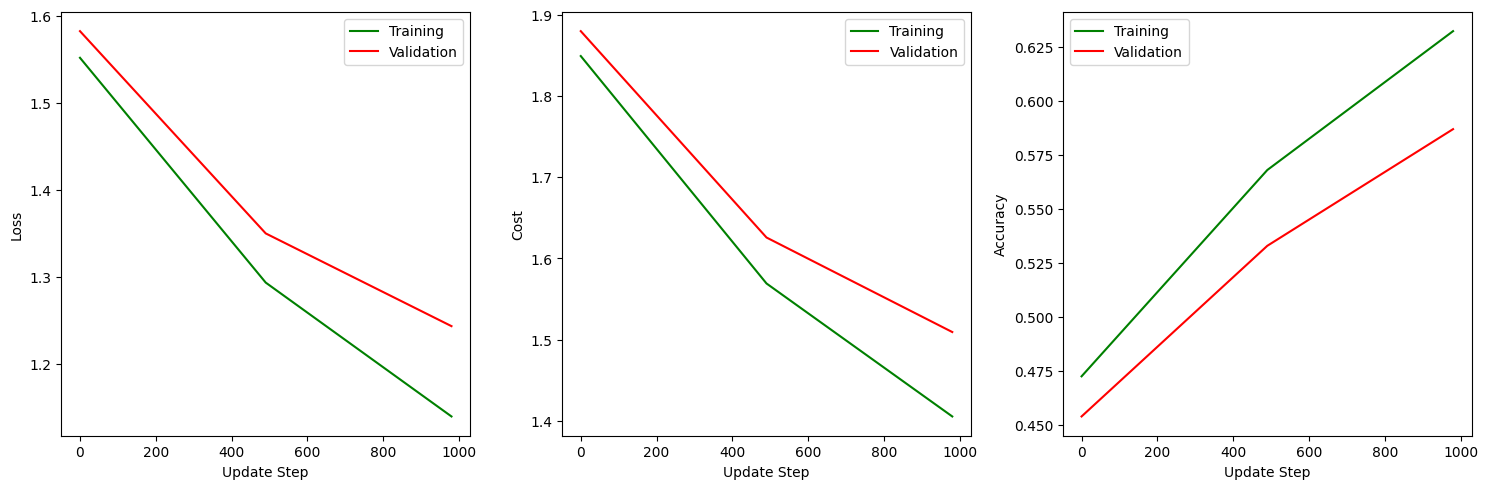

Filter size: 4, Num. filters: 40, Test acc: 0.5803, Training time: 47.35 (s), Label smoothing: 0.1
Training using: m=256, lam=0.0025, label_smoothing=0.025
Cycle 1/1, Train. Loss: 1.5147, Val. Loss: 1.5496, Train. Acc: 0.4731, Val. Acc: 0.4530
Cycle 1/1, Train. Loss: 1.2605, Val. Loss: 1.3241, Train. Acc: 0.5618, Val. Acc: 0.5360
Cycle 1/1, Train. Loss: 1.0857, Val. Loss: 1.1982, Train. Acc: 0.6319, Val. Acc: 0.5820


KeyboardInterrupt: 

In [23]:
import time

explore_m = [256, 512, 1024]
explore_lam = [0.0001, 0.001, 0.0025, 0.005, 0.01]
explore_label_smoothing = [0.025, 0.05, 0.1]

performance_results = []
training_times = []

for m in explore_m:
    for lam in explore_lam:
        for label_smoothing in explore_label_smoothing:
            f = 4
            n_f = 40
            GDparams = {
                'n_batch': 100,
            }

            # Note that we must keep this in the loop as mini_batch_gd
            # will be updating the step sizes and we want to have the same
            # starting point for each combination of parameters.
            cyclical_lr = {
                'eta_min': 1e-5,
                'eta_max': 1e-1,
                'n_s': 800, # step size for cyclical learning rate
                'increasing_step_sizes': True,
                'cycles': 1
            }

            print(f"Training using: m={m}, lam={lam}, label_smoothing={label_smoothing}")

            rng = np.random.default_rng(42)

            net = NeuralNetwork()
            net.add_layer([
                ConvolutionalLayer(f=f, n_f=n_f, activation="relu", lam=lam),
                FlattenLayer(),
                FullyConnectedLayer(d=(32//f)*(32//f)*n_f, m=m, activation="relu", lam=lam),
                FullyConnectedLayer(d=m, m=NUM_CLASSES, activation="softmax", lam=lam),
            ])

            start_time = time.time()
            net.cyclic_mini_batch_gd(rng, net.compute_loss, net.compute_cost, data, GDparams, cyclical_lr, verbose=2, label_smoothing=label_smoothing)
            end_time = time.time()

            acc = net.compute_acc(net.apply_network(data.X_test), data.y_test)

            performance_results.append(acc)
            training_times.append(end_time - start_time)

            print(f"Filter size: {f}, Num. filters: {n_f}, Test acc: {acc:.4f}, Training time: {end_time - start_time:.2f} (s), Label smoothing: {label_smoothing}")